# Training, ablating and aligning a small language model (AFML project)

A decoder-only transformer built from scratch and studied on a single free Colab **T4 GPU**: architectural ablations, scaling, length generalization, KV-cache/GQA efficiency, mechanistic analysis, SFT, DPO and its variants, and an LLM-judge evaluation.

**How to run:** Runtime > Change runtime type > **T4 GPU**, then run the cells top to bottom. Everything (data, tokenizer, checkpoints, caches) is saved to `MyDrive/afml_slm`, so runs are resumable after a disconnect and finished runs are skipped. The helper modules (`slm.py`, `trainlib.py`, `alignlib.py`, `dpolib.py`, `judgelib.py`) are written to Drive by `%%writefile` cells; the same files are in `src/` of the repo. Total GPU time is roughly 3 to 4 hours.

**Notes**
- The outputs shown were produced by our runs. Training runs are single-seed.
- Section 12 downloads Qwen2.5-7B-Instruct (about 15 GB) and needs the GPU. No API key is used.
- The manual-review scores (section 15) are filled in by people, so that part is not reproducible from code alone.

| # | Section |
|---|---|
| 1 | Data and tokenizer |
| 2 | Model and sanity checks |
| 3 | Training library and baseline |
| 4 | Architectural ablations (S model) |
| 5 | Scaling study (S / M / L) |
| 6 | Length generalization |
| 7 | KV-cache and GQA benchmark |
| 8 | Continued pretraining on a general-text mix |
| 9 | Supervised fine-tuning (Alpaca) |
| 10 | DPO, beta sweep, IPO, SimPO |
| 11 | Mechanistic analysis |
| 12 | Local LLM judge and win rates |
| 13 | On-policy preference data vs UltraFeedback |
| 14 | Report figures |
| 15 | Blind manual review |

In [ ]:
!pip -q install datasets tokenizers bitsandbytes accelerate
import torch
print("GPU:", torch.cuda.get_device_name(0) if torch.cuda.is_available() else "NONE -> Runtime > Change runtime type > T4 GPU")

## 1. Data and tokenizer

300k TinyStories stories, a byte-level BPE tokenizer (vocab 4096, trained with the Hugging Face `tokenizers` library) with reserved chat tokens, and uint16 token files.

In [ ]:
!pip -q install datasets tokenizers

import os, itertools, numpy as np, torch
from google.colab import drive
drive.mount('/content/drive')

ROOT = '/content/drive/MyDrive/afml_slm'
os.makedirs(ROOT, exist_ok=True)
print("GPU:", torch.cuda.get_device_name(0) if torch.cuda.is_available() else "NONE - change runtime to T4!")

from datasets import load_dataset
from tokenizers import Tokenizer, models, trainers, pre_tokenizers, decoders

N_TRAIN_STORIES = 300_000   # ~60M tokens, plenty for all ablations on a T4
N_VAL_STORIES   = 5_000
VOCAB = 4096
SPECIAL = ["<|pad|>", "<|eot|>", "<|user|>", "<|assistant|>"]  # chat tokens reserved now for SFT/DPO later

# ---- 1) load data (streamed, so no giant download) ----
ts = load_dataset("roneneldan/TinyStories", split="train", streaming=True)
train_texts = [x["text"].strip() for x in itertools.islice(ts, N_TRAIN_STORIES)]
tv = load_dataset("roneneldan/TinyStories", split="validation", streaming=True)
val_texts = [x["text"].strip() for x in itertools.islice(tv, N_VAL_STORIES)]
alp = load_dataset("tatsu-lab/alpaca", split="train")
alp_texts = [(a["instruction"] + " " + a["input"] + " " + a["output"]).strip() for a in alp.select(range(20000))]
print(len(train_texts), len(val_texts), len(alp_texts))

# ---- 2) train our own byte-level BPE tokenizer ----
tok = Tokenizer(models.BPE())
tok.pre_tokenizer = pre_tokenizers.ByteLevel(add_prefix_space=False)
tok.decoder = decoders.ByteLevel()
trainer = trainers.BpeTrainer(vocab_size=VOCAB, special_tokens=SPECIAL,
                              initial_alphabet=pre_tokenizers.ByteLevel.alphabet())
tok.train_from_iterator(itertools.chain(train_texts[:100_000], alp_texts), trainer)
tok.save(f"{ROOT}/tokenizer.json")
EOT = tok.token_to_id("<|eot|>")
print("vocab size:", tok.get_vocab_size(), "| eot id:", EOT)
print("sample:", tok.encode("Once upon a time, there was a little girl named Lily.").tokens)

# ---- 3) binarize to uint16 memmap files ----
def binarize(texts, path, bs=10_000):
    chunks = []
    for i in range(0, len(texts), bs):
        for enc in tok.encode_batch(texts[i:i+bs]):
            chunks.append(np.array(enc.ids + [EOT], dtype=np.uint16))
    arr = np.concatenate(chunks)
    arr.tofile(path)
    return len(arr)

n_tr = binarize(train_texts, f"{ROOT}/train.bin")
n_va = binarize(val_texts,   f"{ROOT}/val.bin")
print(f"train tokens: {n_tr/1e6:.1f}M | val tokens: {n_va/1e6:.2f}M")

Mounted at /content/drive
GPU: Tesla T4


300000 5000 20000
vocab size: 4096 | eot id: 1
sample: ['Once', 'Ġupon', 'Ġa', 'Ġtime', ',', 'Ġthere', 'Ġwas', 'Ġa', 'Ġlittle', 'Ġgirl', 'Ġnamed', 'ĠLily', '.']
train tokens: 69.7M | val tokens: 1.03M


## 2. Model and sanity checks

`slm.py`: learned/RoPE positions, LayerNorm/RMSNorm, GELU/SwiGLU, MHA/GQA/MQA, KV-cache. The check confirms cached decoding matches the full forward pass.

In [ ]:
%%writefile /content/drive/MyDrive/afml_slm/slm.py
import math, torch, torch.nn as nn, torch.nn.functional as F
from dataclasses import dataclass

@dataclass
class Cfg:
    vocab: int = 4096
    n_layer: int = 6
    n_head: int = 4
    n_kv_head: int = 4          # == n_head -> MHA ; < n_head -> GQA ; 1 -> MQA
    d_model: int = 256
    block_size: int = 256
    pos: str = "learned"        # learned | rope
    norm: str = "ln"            # ln | rms
    mlp: str = "gelu"           # gelu | swiglu
    rope_base: float = 10000.0

SIZES = {"S": dict(d_model=256, n_layer=6,  n_head=4),   # ~5.7M
         "M": dict(d_model=384, n_layer=8,  n_head=6),   # ~15.7M
         "L": dict(d_model=512, n_layer=12, n_head=8)}   # ~39.8M

def make_cfg(size="S", **kw):
    c = Cfg(**SIZES[size]); c.n_kv_head = c.n_head
    for k, v in kw.items(): setattr(c, k, v)
    return c

class RMSNorm(nn.Module):
    def __init__(s, d, eps=1e-6):
        super().__init__(); s.w = nn.Parameter(torch.ones(d)); s.eps = eps
    def forward(s, x):
        xf = x.float()
        return (xf * torch.rsqrt(xf.pow(2).mean(-1, keepdim=True) + s.eps)).type_as(x) * s.w

def Norm(c): return RMSNorm(c.d_model) if c.norm == "rms" else nn.LayerNorm(c.d_model)

def apply_rope(x, pos, base, scale=1.0):
    # x: (B,H,T,hd); pos: (T,) ; scale<1 => position interpolation
    hd = x.shape[-1]
    inv = 1.0 / (base ** (torch.arange(0, hd, 2, device=x.device).float() / hd))
    ang = (pos.float() * scale)[:, None] * inv[None, :]
    cos, sin = ang.cos().to(x.dtype), ang.sin().to(x.dtype)
    x1, x2 = x[..., :hd // 2], x[..., hd // 2:]
    return torch.cat([x1 * cos - x2 * sin, x2 * cos + x1 * sin], -1)

class Attn(nn.Module):
    def __init__(s, c):
        super().__init__()
        s.c = c; s.nh = c.n_head; s.nkv = c.n_kv_head; s.hd = c.d_model // c.n_head
        assert s.nh % s.nkv == 0
        s.q = nn.Linear(c.d_model, s.nh * s.hd, bias=False)
        s.k = nn.Linear(c.d_model, s.nkv * s.hd, bias=False)
        s.v = nn.Linear(c.d_model, s.nkv * s.hd, bias=False)
        s.o = nn.Linear(s.nh * s.hd, c.d_model, bias=False)
        s.register_buffer("head_mask", torch.ones(s.nh), persistent=False)  # for head ablation
        s.store_attn = False; s.last_attn = None                             # for mech. analysis

    def forward(s, x, pos, cache=None, rope_scale=1.0):
        B, T, _ = x.shape
        q = s.q(x).view(B, T, s.nh, s.hd).transpose(1, 2)
        k = s.k(x).view(B, T, s.nkv, s.hd).transpose(1, 2)
        v = s.v(x).view(B, T, s.nkv, s.hd).transpose(1, 2)
        if s.c.pos == "rope":
            q = apply_rope(q, pos, s.c.rope_base, rope_scale)
            k = apply_rope(k, pos, s.c.rope_base, rope_scale)
        past = 0
        if cache is not None:
            past = cache[0].shape[2]
            k = torch.cat([cache[0], k], 2); v = torch.cat([cache[1], v], 2)
        assert T == 1 or past == 0, "cache only supports prefill-then-single-token decode"
        new_cache = (k, v)                      # cache stores only n_kv heads (the GQA saving)
        rep = s.nh // s.nkv
        fast = (T == 1 and rep > 1 and not s.store_attn)   # GQA decode: attend per KV group
        if fast:
            kk, vv = k, v
        else:
            kk = k.repeat_interleave(rep, 1) if rep > 1 else k
            vv = v.repeat_interleave(rep, 1) if rep > 1 else v
        if s.store_attn:
            att = (q @ kk.transpose(-1, -2)) / math.sqrt(s.hd)
            S = kk.shape[2]
            m = torch.ones(T, S, dtype=torch.bool, device=x.device).tril(S - T)
            att = att.float().masked_fill(~m, float("-inf")).softmax(-1)
            s.last_attn = att.detach()
            y = att.to(vv.dtype) @ vv
        elif fast:
            y = F.scaled_dot_product_attention(q.reshape(B, s.nkv, rep, s.hd), kk, vv).reshape(B, s.nh, 1, s.hd)
        else:
            y = F.scaled_dot_product_attention(q, kk, vv, is_causal=(T > 1))
        y = y * s.head_mask.view(1, -1, 1, 1).to(y.dtype)
        return s.o(y.transpose(1, 2).reshape(B, T, -1)), new_cache

class MLP(nn.Module):
    def __init__(s, c):
        super().__init__()
        d = c.d_model; s.swiglu = (c.mlp == "swiglu")
        if s.swiglu:
            h = ((int(8 * d / 3) + 31) // 32) * 32     # keeps params ~equal to 4d GELU MLP
            s.w1 = nn.Linear(d, h, bias=False); s.w3 = nn.Linear(d, h, bias=False); s.w2 = nn.Linear(h, d, bias=False)
        else:
            s.w1 = nn.Linear(d, 4 * d, bias=False); s.w2 = nn.Linear(4 * d, d, bias=False)
    def forward(s, x):
        return s.w2(F.silu(s.w1(x)) * s.w3(x)) if s.swiglu else s.w2(F.gelu(s.w1(x)))

class Block(nn.Module):
    def __init__(s, c):
        super().__init__()
        s.n1 = Norm(c); s.attn = Attn(c); s.n2 = Norm(c); s.mlp = MLP(c)
    def forward(s, x, pos, cache=None, rope_scale=1.0):
        a, nc = s.attn(s.n1(x), pos, cache, rope_scale)
        x = x + a
        return x + s.mlp(s.n2(x)), nc

class GPT(nn.Module):
    def __init__(s, c):
        super().__init__()
        s.c = c; s.rope_scale = 1.0
        s.tok = nn.Embedding(c.vocab, c.d_model)
        s.pos_emb = nn.Embedding(c.block_size, c.d_model) if c.pos == "learned" else None
        s.blocks = nn.ModuleList([Block(c) for _ in range(c.n_layer)])
        s.nf = Norm(c)
        s.head = nn.Linear(c.d_model, c.vocab, bias=False)
        s.head.weight = s.tok.weight            # weight tying
        s.apply(s._init)
        for n, p in s.named_parameters():       # scaled init for residual projections
            if n.endswith("attn.o.weight") or n.endswith("mlp.w2.weight"):
                nn.init.normal_(p, 0.0, 0.02 / math.sqrt(2 * c.n_layer))

    def _init(s, m):
        if isinstance(m, (nn.Linear, nn.Embedding)): nn.init.normal_(m.weight, 0.0, 0.02)

    def n_params(s, non_embed=False):
        n = sum(p.numel() for p in s.parameters())
        if non_embed:
            n -= s.tok.weight.numel()
            if s.pos_emb is not None: n -= s.pos_emb.weight.numel()
        return n

    def forward(s, idx, targets=None, cache=None, start_pos=0, full_logits=False, use_cache=False):
        B, T = idx.shape
        pos = torch.arange(start_pos, start_pos + T, device=idx.device)
        x = s.tok(idx)
        if s.c.pos == "learned":
            assert start_pos + T <= s.c.block_size, "learned pos-emb: sequence longer than block_size"
            x = x + s.pos_emb(pos)
        new = []
        for i, b in enumerate(s.blocks):
            x, nc = b(x, pos, None if cache is None else cache[i], s.rope_scale)
            if use_cache or cache is not None: new.append(nc)
        x = s.nf(x)
        if targets is not None:
            logits = s.head(x)
            loss = F.cross_entropy(logits.float().view(-1, logits.size(-1)), targets.reshape(-1), ignore_index=-100)
            return logits, loss, (new or None)
        logits = s.head(x if full_logits else x[:, -1:])
        return logits, None, (new or None)

    @torch.no_grad()
    def generate(s, idx, max_new=100, temperature=1.0, top_k=None, use_cache=True, stop_id=None):
        s.eval()
        if s.c.pos == "learned": max_new = min(max_new, s.c.block_size - idx.shape[1])
        cache = None
        if use_cache:
            logits, _, cache = s(idx, use_cache=True)
        for _ in range(max_new):
            if not use_cache:
                ctx = idx[:, -s.c.block_size:] if s.c.pos == "learned" else idx
                logits, _, _ = s(ctx)
            lg = logits[:, -1].float()
            if temperature == 0:
                nxt = lg.argmax(-1, keepdim=True)
            else:
                lg = lg / temperature
                if top_k:
                    v, _ = torch.topk(lg, top_k); lg[lg < v[:, [-1]]] = -float("inf")
                nxt = torch.multinomial(F.softmax(lg, -1), 1)
            idx = torch.cat([idx, nxt], 1)
            if stop_id is not None and (nxt == stop_id).all(): break
            if use_cache:
                logits, _, cache = s(nxt, cache=cache, start_pos=idx.shape[1] - 1, use_cache=True)
        return idx

Writing /content/drive/MyDrive/afml_slm/slm.py


In [ ]:
import sys, time, torch, importlib
ROOT = '/content/drive/MyDrive/afml_slm'
sys.path.insert(0, ROOT)
import slm; importlib.reload(slm)
from slm import GPT, make_cfg
dev = 'cuda'

# 1) param counts
variants = {"baseline": {}, "modern(rope+rms+swiglu)": dict(pos="rope", norm="rms", mlp="swiglu")}
for size in "SML":
    for name, kw in variants.items():
        m = GPT(make_cfg(size, **kw))
        print(f"{size} {name:26s} total={m.n_params()/1e6:5.2f}M  non-embed={m.n_params(True)/1e6:5.2f}M")

# 2) KV-cache correctness (cached decode must match full forward)
for name, kw in {"baseline": {}, "rope+rms+swiglu+GQA": dict(pos="rope", norm="rms", mlp="swiglu", n_kv_head=2)}.items():
    m = GPT(make_cfg("S", **kw)).to(dev).eval()
    idx = torch.randint(4, 4096, (2, 40), device=dev)
    with torch.no_grad():
        full = m(idx, full_logits=True)[0][:, -1]
        _, _, cache = m(idx[:, :20], use_cache=True)
        for t in range(20, 40):
            lg, _, cache = m(idx[:, t:t+1], cache=cache, start_pos=t, use_cache=True)
    print(f"KV-cache check [{name}] max abs diff: {(full - lg[:, -1]).abs().max().item():.2e}  (should be ~1e-5 or less)")

# 3) T4 throughput (fp16 autocast, 5.7M model, batch 64 x 256)
m = GPT(make_cfg("S", pos="rope", norm="rms", mlp="swiglu")).to(dev)
opt = torch.optim.AdamW(m.parameters(), lr=1e-3)
x = torch.randint(4, 4096, (64, 256), device=dev)
for i in range(13):
    if i == 3: torch.cuda.synchronize(); t0 = time.time()
    with torch.autocast('cuda', dtype=torch.float16):
        _, loss, _ = m(x, x)
    loss.backward(); opt.step(); opt.zero_grad(set_to_none=True)
torch.cuda.synchronize(); dt = (time.time() - t0) / 10
print(f"S model: {dt*1000:.0f} ms/step -> {64*256/dt/1e3:.0f}k tokens/sec")

S baseline                   total= 5.84M  non-embed= 4.73M
S modern(rope+rms+swiglu)    total= 5.87M  non-embed= 4.82M
M baseline                   total=15.84M  non-embed=14.17M
M modern(rope+rms+swiglu)    total=15.74M  non-embed=14.16M
L baseline                   total=40.00M  non-embed=37.77M
L modern(rope+rms+swiglu)    total=40.06M  non-embed=37.96M
KV-cache check [baseline] max abs diff: 1.07e-06  (should be ~1e-5 or less)
KV-cache check [rope+rms+swiglu+GQA] max abs diff: 7.15e-07  (should be ~1e-5 or less)
S model: 109 ms/step -> 151k tokens/sec


## 3. Training library and baseline

In [ ]:
%%writefile /content/drive/MyDrive/afml_slm/trainlib.py
import os, json, math, time, numpy as np, torch
from dataclasses import asdict
from slm import GPT, Cfg
ROOT = '/content/drive/MyDrive/afml_slm'
dev = 'cuda'
os.makedirs(f"{ROOT}/runs", exist_ok=True); os.makedirs(f"{ROOT}/ckpt", exist_ok=True)

_train = np.fromfile(f"{ROOT}/train.bin", dtype=np.uint16)   # loaded into RAM (~140MB)
_val   = np.fromfile(f"{ROOT}/val.bin",   dtype=np.uint16)

def get_batch(bs, T, gen):
    ix = torch.randint(0, len(_train) - T - 1, (bs,), generator=gen).numpy()
    idx = ix[:, None] + np.arange(T)[None, :]
    x = torch.from_numpy(_train[idx].astype(np.int64)); y = torch.from_numpy(_train[idx + 1].astype(np.int64))
    return x.to(dev, non_blocking=True), y.to(dev, non_blocking=True)

@torch.no_grad()
def evaluate(model, T=256, max_seqs=None, bs=64, data=None):
    """mean next-token loss over non-overlapping length-T chunks of the val set"""
    d = _val if data is None else data
    model.eval()
    n = (len(d) - 1) // T
    if max_seqs: n = min(n, max_seqs)
    arr = torch.from_numpy(d[:n * T + 1].astype(np.int64))
    X, Y = arr[:n * T].view(n, T), arr[1:n * T + 1].view(n, T)
    tot, cnt = 0.0, 0
    for i in range(0, n, bs):
        x, y = X[i:i+bs].to(dev), Y[i:i+bs].to(dev)
        with torch.autocast('cuda', dtype=torch.float16):
            _, loss, _ = model(x, y)
        tot += loss.item() * x.numel(); cnt += x.numel()
    model.train()
    return tot / cnt

def load_model(name):
    ck = torch.load(f"{ROOT}/ckpt/{name}.pt", map_location=dev)
    m = GPT(Cfg(**ck['cfg'])).to(dev); m.load_state_dict(ck['model']); return m.eval()

def train(name, cfg, tokens=40e6, bs=64, lr=1.5e-3, warmup=100, min_lr_frac=0.1,
          eval_every=250, wd=0.1, seed=1337, force=False):
    res_path = f"{ROOT}/runs/{name}.json"
    if os.path.exists(res_path) and not force:
        print(f"[{name}] already done -> skipping"); return json.load(open(res_path))
    torch.manual_seed(seed)
    T = cfg.block_size
    steps = int(tokens // (bs * T))
    model = GPT(cfg).to(dev)
    decay   = [p for p in model.parameters() if p.dim() >= 2]
    nodecay = [p for p in model.parameters() if p.dim() < 2]
    opt = torch.optim.AdamW([{'params': decay, 'weight_decay': wd}, {'params': nodecay, 'weight_decay': 0.0}],
                            lr=lr, betas=(0.9, 0.95), fused=True)
    scaler = torch.cuda.amp.GradScaler()
    start, curve, train_time = 0, [], 0.0
    rpath = f"{ROOT}/ckpt/{name}_resume.pt"
    if os.path.exists(rpath):
        r = torch.load(rpath, map_location=dev)
        model.load_state_dict(r['model']); opt.load_state_dict(r['opt']); scaler.load_state_dict(r['scaler'])
        start, curve, train_time = r['step'], r['curve'], r['train_time']
        print(f"[{name}] resumed from step {start}")
    print(f"[{name}] params={model.n_params()/1e6:.2f}M (non-embed {model.n_params(True)/1e6:.2f}M) steps={steps}")
    gen = torch.Generator().manual_seed(seed + start)
    torch.cuda.reset_peak_memory_stats()
    acc, acc_n = torch.zeros((), device=dev), 0
    model.train(); torch.cuda.synchronize(); t_seg = time.time()
    for step in range(start, steps):
        cur = lr * (step + 1) / warmup if step < warmup else \
              lr * (min_lr_frac + (1 - min_lr_frac) * 0.5 * (1 + math.cos(math.pi * (step - warmup) / max(1, steps - warmup))))
        for g in opt.param_groups: g['lr'] = cur
        x, y = get_batch(bs, T, gen)
        with torch.autocast('cuda', dtype=torch.float16):
            _, loss, _ = model(x, y)
        scaler.scale(loss).backward()
        scaler.unscale_(opt); torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
        scaler.step(opt); scaler.update(); opt.zero_grad(set_to_none=True)
        acc += loss.detach(); acc_n += 1
        last = (step == steps - 1)
        if (step + 1) % eval_every == 0 or last:
            torch.cuda.synchronize(); train_time += time.time() - t_seg
            vl = evaluate(model, T, max_seqs=None if last else 1024)
            tl = (acc / acc_n).item(); acc.zero_(); acc_n = 0
            curve.append(dict(step=step + 1, tokens=(step + 1) * bs * T, train_loss=tl, val_loss=vl))
            print(f"[{name}] step {step+1}/{steps} train {tl:.3f} val {vl:.3f} lr {cur:.2e}")
            torch.cuda.synchronize(); t_seg = time.time()
        if (step + 1) % 500 == 0 and not last:
            torch.cuda.synchronize(); train_time += time.time() - t_seg; t_seg = time.time()
            torch.save(dict(model=model.state_dict(), opt=opt.state_dict(), scaler=scaler.state_dict(),
                            step=step + 1, curve=curve, train_time=train_time), rpath)
    final_val = curve[-1]['val_loss']
    res = dict(name=name, cfg=asdict(cfg), params=model.n_params(), non_embed=model.n_params(True),
               steps=steps, tokens=steps * bs * T, val_loss=final_val, val_ppl=math.exp(final_val),
               train_time_s=train_time, tok_per_s=steps * bs * T / train_time,
               peak_mem_mb=torch.cuda.max_memory_allocated() / 2**20,
               flops=6 * model.n_params(True) * steps * bs * T, curve=curve)
    json.dump(res, open(res_path, 'w'))
    torch.save(dict(cfg=asdict(cfg), model=model.state_dict()), f"{ROOT}/ckpt/{name}.pt")
    if os.path.exists(rpath): os.remove(rpath)
    print(f"[{name}] DONE val_loss={final_val:.4f} ppl={res['val_ppl']:.2f} "
          f"{res['tok_per_s']/1e3:.0f}k tok/s peak_mem={res['peak_mem_mb']:.0f}MB")
    return res

Writing /content/drive/MyDrive/afml_slm/trainlib.py


In [ ]:
import sys, importlib
ROOT = '/content/drive/MyDrive/afml_slm'
sys.path.insert(0, ROOT)
import slm, trainlib; importlib.reload(slm); importlib.reload(trainlib)
from slm import make_cfg
from trainlib import train, load_model, dev
import torch
from tokenizers import Tokenizer
tok = Tokenizer.from_file(f"{ROOT}/tokenizer.json")

res = train("S_baseline", make_cfg("S"))     # ~5 min

m = load_model("S_baseline")
ids = torch.tensor([tok.encode("Once upon a time, there was a little").ids], device=dev)
out = m.generate(ids, max_new=120, temperature=0.8, top_k=40)
print("\n--- SAMPLE ---\n", tok.decode(out[0].tolist()))

/content/drive/MyDrive/afml_slm/trainlib.py:52: FutureWarning: `torch.cuda.amp.GradScaler(args...)` is deprecated. Please use `torch.amp.GradScaler('cuda', args...)` instead.
  scaler = torch.cuda.amp.GradScaler()


[S_baseline] params=5.84M (non-embed 4.73M) steps=2441
[S_baseline] step 250/2441 train 4.336 val 3.270 lr 1.49e-03
[S_baseline] step 500/2441 train 2.921 val 2.737 lr 1.41e-03
[S_baseline] step 750/2441 train 2.559 val 2.487 lr 1.26e-03
[S_baseline] step 1000/2441 train 2.364 val 2.330 lr 1.07e-03
[S_baseline] step 1250/2441 train 2.229 val 2.222 lr 8.44e-04
[S_baseline] step 1500/2441 train 2.136 val 2.139 lr 6.21e-04
[S_baseline] step 1750/2441 train 2.063 val 2.074 lr 4.21e-04
[S_baseline] step 2000/2441 train 2.003 val 2.030 lr 2.65e-04
[S_baseline] step 2250/2441 train 1.971 val 1.997 lr 1.72e-04
[S_baseline] step 2441/2441 train 1.938 val 1.995 lr 1.50e-04
[S_baseline] DONE val_loss=1.9952 ppl=7.35 223k tok/s peak_mem=1967MB

--- SAMPLE ---
 Once upon a time, there was a little girl named Lily. She loved to play outside with her friends. One day, they found a big hole in the ground. Lily was curious about what was inside.

As they were buried, they saw a big, mean dog. The dog w

## 4. Architectural ablations (S model, 40M tokens each)

Each change alone, all three together, and with GQA; a second baseline seed estimates the noise floor (about 0.008).

In [ ]:
import sys, importlib, json, glob, pandas as pd
ROOT = '/content/drive/MyDrive/afml_slm'
sys.path.insert(0, ROOT)
import slm, trainlib; importlib.reload(slm); importlib.reload(trainlib)
from slm import make_cfg
from trainlib import train

ablations = {
    "S_baseline_seed2": (dict(), dict(seed=2)),                     # noise estimate
    "S_rope":           (dict(pos="rope"), {}),
    "S_rms":            (dict(norm="rms"), {}),
    "S_swiglu":         (dict(mlp="swiglu"), {}),
    "S_gqa2":           (dict(n_kv_head=2), {}),                    # 4 query heads, 2 KV heads
    "S_modern":         (dict(pos="rope", norm="rms", mlp="swiglu"), {}),
    "S_modern_gqa2":    (dict(pos="rope", norm="rms", mlp="swiglu", n_kv_head=2), {}),
}
for name, (cfg_kw, train_kw) in ablations.items():
    train(name, make_cfg("S", **cfg_kw), **train_kw)

# ---- results table ----
rows = []
for f in sorted(glob.glob(f"{ROOT}/runs/S_*.json")):
    r = json.load(open(f)); c = r['cfg']
    rows.append(dict(run=r['name'], params_M=r['params']/1e6, val_loss=r['val_loss'], val_ppl=r['val_ppl'],
                     kHz_tok_s=r['tok_per_s']/1e3, peak_mem_MB=r['peak_mem_mb']))
df = pd.DataFrame(rows).set_index('run')
base = df.loc['S_baseline', 'val_loss']
df['d_loss_vs_base'] = df['val_loss'] - base
print(df.round(4).sort_values('val_loss').to_string())
df.to_csv(f"{ROOT}/ablation_S.csv")

[S_baseline_seed2] params=5.84M (non-embed 4.73M) steps=2441
[S_baseline_seed2] step 250/2441 train 4.339 val 3.270 lr 1.49e-03
[S_baseline_seed2] step 500/2441 train 2.918 val 2.728 lr 1.41e-03
[S_baseline_seed2] step 750/2441 train 2.547 val 2.470 lr 1.26e-03
[S_baseline_seed2] step 1000/2441 train 2.350 val 2.316 lr 1.07e-03
[S_baseline_seed2] step 1250/2441 train 2.221 val 2.211 lr 8.44e-04
[S_baseline_seed2] step 1500/2441 train 2.125 val 2.126 lr 6.21e-04
[S_baseline_seed2] step 1750/2441 train 2.047 val 2.065 lr 4.21e-04
[S_baseline_seed2] step 2000/2441 train 1.992 val 2.020 lr 2.65e-04
[S_baseline_seed2] step 2250/2441 train 1.955 val 1.987 lr 1.72e-04
[S_baseline_seed2] step 2441/2441 train 1.930 val 1.988 lr 1.50e-04
[S_baseline_seed2] DONE val_loss=1.9876 ppl=7.30 219k tok/s peak_mem=1989MB
[S_rope] params=5.77M (non-embed 4.73M) steps=2441
[S_rope] step 250/2441 train 4.085 val 2.986 lr 1.49e-03
[S_rope] step 500/2441 train 2.702 val 2.549 lr 1.41e-03
[S_rope] step 750/244

## 5. Scaling study (S = 5.8M, M = 15.8M, L = 40M)

Fixed 40M training tokens at every size; power-law fits use 3 points.

In [ ]:
import sys, importlib, json, glob, math, numpy as np, pandas as pd
ROOT = '/content/drive/MyDrive/afml_slm'
sys.path.insert(0, ROOT)
import slm, trainlib; importlib.reload(slm); importlib.reload(trainlib)
from slm import make_cfg
from trainlib import train

MODERN = dict(pos="rope", norm="rms", mlp="swiglu")
plan = [  # (name, size, cfg_kwargs, lr)  -- lr fixed per size across variants
    ("M_baseline", "M", {},                1e-3),
    ("M_rope",     "M", dict(pos="rope"),  1e-3),
    ("M_swiglu",   "M", dict(mlp="swiglu"),1e-3),
    ("M_modern",   "M", MODERN,            1e-3),
    ("L_baseline", "L", {},                7e-4),   # comment out the L lines if short on time
    ("L_modern",   "L", MODERN,            7e-4),
]
for name, size, kw, lr in plan:
    train(name, make_cfg(size, **kw), lr=lr)

# ---- results: loss table, gain vs baseline per size, power-law fit ----
R = {}
for f in glob.glob(f"{ROOT}/runs/[SML]_*.json"):
    r = json.load(open(f)); R[r['name']] = r
rows = []
for var in ["baseline", "rope", "swiglu", "modern"]:
    for size in "SML":
        r = R.get(f"{size}_{var}")
        if r: rows.append(dict(variant=var, size=size, non_embed_M=r['non_embed']/1e6, flops=r['flops'],
                               val_loss=r['val_loss'], tok_s_k=r['tok_per_s']/1e3, mem_MB=r['peak_mem_mb']))
df = pd.DataFrame(rows); df.to_csv(f"{ROOT}/scaling.csv", index=False)
cols = [c for c in "SML" if c in set(df['size'])]
piv = df.pivot(index='variant', columns='size', values='val_loss')[cols]
print("Val loss:\n", piv.round(4).to_string())
print("\nDelta vs baseline (negative = better):\n", (piv - piv.loc['baseline']).round(4).to_string())
print("\nFits  loss = A * C^b  (only 3 points -> rough exponents):")
for var in ["baseline", "modern"]:
    d = df[df.variant == var]
    if len(d) >= 3:
        b, a = np.polyfit(np.log(d.flops), np.log(d.val_loss), 1)
        print(f"  {var:9s} loss ~ {math.exp(a):.2f} * C^{b:.4f}")

/content/drive/MyDrive/afml_slm/trainlib.py:52: FutureWarning: `torch.cuda.amp.GradScaler(args...)` is deprecated. Please use `torch.amp.GradScaler('cuda', args...)` instead.
  scaler = torch.cuda.amp.GradScaler()


[M_baseline] params=15.84M (non-embed 14.17M) steps=2441
[M_baseline] step 250/2441 train 4.214 val 3.179 lr 9.91e-04
[M_baseline] step 500/2441 train 2.829 val 2.624 lr 9.37e-04
[M_baseline] step 750/2441 train 2.444 val 2.364 lr 8.40e-04
[M_baseline] step 1000/2441 train 2.242 val 2.210 lr 7.10e-04
[M_baseline] step 1250/2441 train 2.107 val 2.103 lr 5.63e-04
[M_baseline] step 1500/2441 train 2.016 val 2.022 lr 4.14e-04
[M_baseline] step 1750/2441 train 1.941 val 1.959 lr 2.80e-04
[M_baseline] step 2000/2441 train 1.881 val 1.916 lr 1.77e-04
[M_baseline] step 2250/2441 train 1.848 val 1.882 lr 1.15e-04
[M_baseline] step 2441/2441 train 1.816 val 1.881 lr 1.00e-04
[M_baseline] DONE val_loss=1.8806 ppl=6.56 104k tok/s peak_mem=3154MB
[M_rope] params=15.74M (non-embed 14.17M) steps=2441
[M_rope] step 250/2441 train 3.960 val 2.919 lr 9.91e-04
[M_rope] step 500/2441 train 2.622 val 2.466 lr 9.37e-04
[M_rope] step 750/2441 train 2.309 val 2.256 lr 8.40e-04
[M_rope] step 1000/2441 train 2.

## 6. Length generalization

Trained at context 256, evaluated at 256 / 512 / 1024: learned embeddings (clamped / interpolated) vs RoPE (plain / position interpolation).

                        ppl@256  ppl@512  ppl@1024
config                                            
learned (clamp)            7.44    16.58     37.13
learned + table interp     7.44     8.25     14.10
RoPE                       6.93    10.15     22.43
RoPE + PI                  6.93     8.02     13.30
modern RoPE                6.69     9.86     20.42
modern RoPE + PI           6.69     7.87     13.15


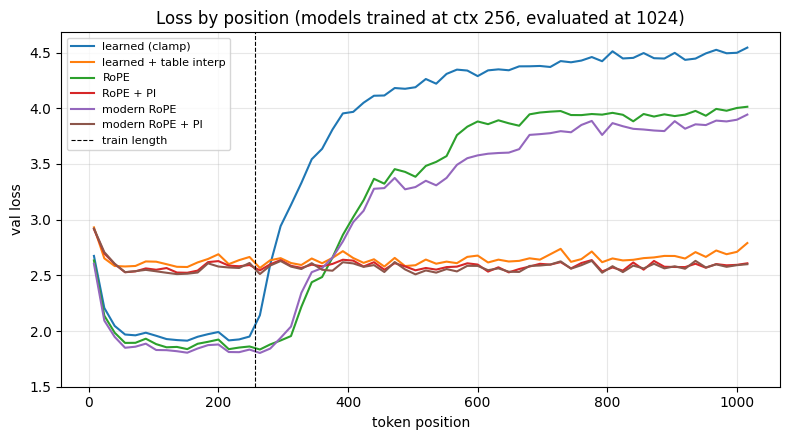

In [ ]:
import sys, importlib, numpy as np, pandas as pd, torch, torch.nn as nn, torch.nn.functional as F
import matplotlib.pyplot as plt
ROOT = '/content/drive/MyDrive/afml_slm'
sys.path.insert(0, ROOT)
import slm, trainlib; importlib.reload(slm); importlib.reload(trainlib)
from trainlib import load_model, dev, _val

def prep(name, mode, L):
    m = load_model(name)
    if m.c.pos == "learned":
        if L > 256:
            w = m.pos_emb.weight.data
            if mode == "interp":
                new = F.interpolate(w.t().unsqueeze(0), size=L, mode='linear', align_corners=True)[0].t()
            else:  # clamp: every position >= 256 reuses the last learned embedding
                new = torch.cat([w, w[-1:].expand(L - 256, -1)], 0)
            m.pos_emb = nn.Embedding(L, w.shape[1]).to(dev)
            m.pos_emb.weight.data.copy_(new)
            m.c.block_size = L
    else:
        m.rope_scale = (256.0 / L) if mode == "pi" else 1.0
    return m.eval()

@torch.no_grad()
def pos_loss(m, L, bs=16, tok_budget=400_000):
    n = min((len(_val) - 1) // L, tok_budget // L)
    arr = torch.from_numpy(_val[:n * L + 1].astype(np.int64))
    X, Y = arr[:n * L].view(n, L), arr[1:n * L + 1].view(n, L)
    tot = torch.zeros(L, device=dev)
    for i in range(0, n, bs):
        x, y = X[i:i + bs].to(dev), Y[i:i + bs].to(dev)
        with torch.autocast('cuda', dtype=torch.float16):
            logits, _, _ = m(x, full_logits=True)
        tot += F.cross_entropy(logits.float().transpose(1, 2), y, reduction='none').sum(0)
    return (tot / n).cpu().numpy()

configs = [
    ("learned (clamp)",        "S_baseline", "clamp"),
    ("learned + table interp", "S_baseline", "interp"),
    ("RoPE",                   "S_rope",     "none"),
    ("RoPE + PI",              "S_rope",     "pi"),
    ("modern RoPE",            "S_modern",   "none"),
    ("modern RoPE + PI",       "S_modern",   "pi"),
]
Ls = [256, 512, 1024]
rows, curves = [], {}
for label, name, mode in configs:
    row = {"config": label}
    for L in Ls:
        pl = pos_loss(prep(name, mode, L), L)
        row[f"ppl@{L}"] = float(np.exp(pl.mean()))
        if L == 1024: curves[label] = pl
    rows.append(row)
df = pd.DataFrame(rows).set_index("config")
print(df.round(2).to_string())
df.to_csv(f"{ROOT}/length_gen.csv")

# loss vs position at length 1024
plt.figure(figsize=(8, 4.5))
for label, pl in curves.items():
    sm = pl.reshape(-1, 16).mean(1)                       # 16-token buckets
    plt.plot(np.arange(len(sm)) * 16 + 8, sm, label=label)
plt.axvline(256, color='k', ls='--', lw=0.8, label='train length')
plt.ylim(1.5, min(5, plt.ylim()[1])); plt.xlabel("token position"); plt.ylabel("val loss")
plt.title("Loss by position (models trained at ctx 256, evaluated at 1024)")
plt.legend(fontsize=8); plt.grid(alpha=.3); plt.tight_layout()
plt.savefig(f"{ROOT}/length_gen.png", dpi=150); plt.show()

## 7. KV-cache and GQA benchmark

The first cell also applies the efficient GQA decode path (already included in `slm.py` above, so the patch is a no-op) and trains the MQA variant. The second cell is the cleaner benchmark (median of repeated windows, longer contexts).

patched slm.py
cache check kv_heads=4: max diff 7.2e-07
cache check kv_heads=2: max diff 8.9e-07
cache check kv_heads=1: max diff 7.2e-07
[S_modern_gqa1] params=5.28M (non-embed 4.23M) steps=2441


/content/drive/MyDrive/afml_slm/trainlib.py:52: FutureWarning: `torch.cuda.amp.GradScaler(args...)` is deprecated. Please use `torch.amp.GradScaler('cuda', args...)` instead.
  scaler = torch.cuda.amp.GradScaler()


[S_modern_gqa1] step 250/2441 train 4.007 val 2.858 lr 1.49e-03
[S_modern_gqa1] step 500/2441 train 2.603 val 2.473 lr 1.41e-03
[S_modern_gqa1] step 750/2441 train 2.343 val 2.302 lr 1.26e-03
[S_modern_gqa1] step 1000/2441 train 2.206 val 2.192 lr 1.07e-03
[S_modern_gqa1] step 1250/2441 train 2.104 val 2.110 lr 8.44e-04
[S_modern_gqa1] step 1500/2441 train 2.033 val 2.046 lr 6.21e-04
[S_modern_gqa1] step 1750/2441 train 1.974 val 1.995 lr 4.21e-04
[S_modern_gqa1] step 2000/2441 train 1.924 val 1.957 lr 2.65e-04
[S_modern_gqa1] step 2250/2441 train 1.899 val 1.930 lr 1.72e-04
[S_modern_gqa1] step 2441/2441 train 1.869 val 1.932 lr 1.50e-04
[S_modern_gqa1] DONE val_loss=1.9322 ppl=6.90 151k tok/s peak_mem=2379MB

kv_cache_MB  (rows = KV heads, cols = context; 8 query heads, batch 16):
ctx        512    1024   2048    4096
kv_heads                             
8         192.0  384.0  768.0  1536.0
4          96.0  192.0  384.0   768.0
2          48.0   96.0  192.0   384.0
1          24.0 

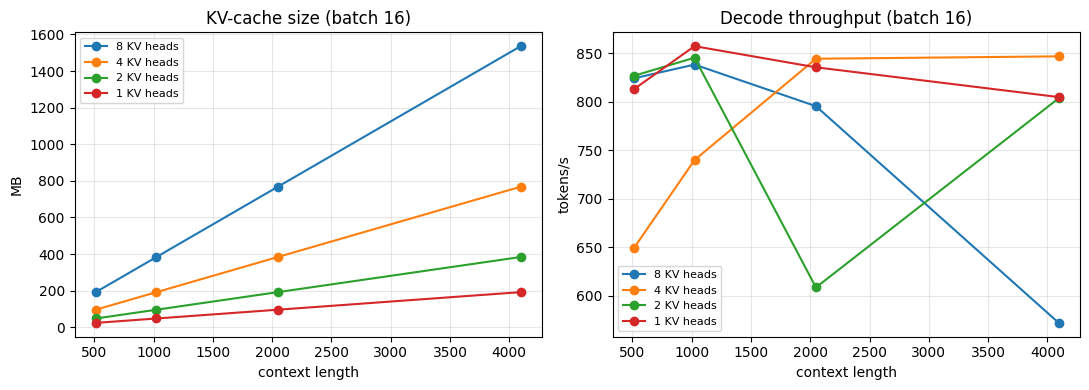

In [ ]:
import sys, importlib, json, time, numpy as np, pandas as pd, torch
import matplotlib.pyplot as plt
ROOT = '/content/drive/MyDrive/afml_slm'
sys.path.insert(0, ROOT)

# ---- 0) patch slm.py: efficient GQA decode (no K/V expansion when T==1) ----
src = open(f"{ROOT}/slm.py").read()
if "fast = (T == 1" not in src:
    a_old = """        rep = s.nh // s.nkv
        kk = k.repeat_interleave(rep, 1) if rep > 1 else k
        vv = v.repeat_interleave(rep, 1) if rep > 1 else v
"""
    a_new = """        rep = s.nh // s.nkv
        fast = (T == 1 and rep > 1 and not s.store_attn)   # GQA decode: attend per KV group
        if fast:
            kk, vv = k, v
        else:
            kk = k.repeat_interleave(rep, 1) if rep > 1 else k
            vv = v.repeat_interleave(rep, 1) if rep > 1 else v
"""
    b_old = """        else:
            y = F.scaled_dot_product_attention(q, kk, vv, is_causal=(T > 1))
"""
    b_new = """        elif fast:
            y = F.scaled_dot_product_attention(q.reshape(B, s.nkv, rep, s.hd), kk, vv).reshape(B, s.nh, 1, s.hd)
        else:
            y = F.scaled_dot_product_attention(q, kk, vv, is_causal=(T > 1))
"""
    assert a_old in src and b_old in src, "slm.py differs from what I expected - paste me the error"
    open(f"{ROOT}/slm.py", "w").write(src.replace(a_old, a_new).replace(b_old, b_new))
    print("patched slm.py")

import slm, trainlib
importlib.reload(slm); importlib.reload(trainlib)
from slm import GPT, make_cfg
from trainlib import train, dev
MODERN = dict(pos="rope", norm="rms", mlp="swiglu")

# ---- 1) correctness: cached decode == full forward (MHA / GQA2 / MQA) ----
for nkv in [4, 2, 1]:
    m = GPT(make_cfg("S", **MODERN, n_kv_head=nkv)).to(dev).eval()
    idx = torch.randint(4, 4096, (2, 40), device=dev)
    with torch.no_grad():
        full = m(idx, full_logits=True)[0][:, -1]
        _, _, cache = m(idx[:, :20], use_cache=True)
        for t in range(20, 40):
            lg, _, cache = m(idx[:, t:t+1], cache=cache, start_pos=t, use_cache=True)
    print(f"cache check kv_heads={nkv}: max diff {(full - lg[:, -1]).abs().max().item():.1e}")

# ---- 2) train MQA variant for the quality study ----
train("S_modern_gqa1", make_cfg("S", **MODERN, n_kv_head=1))

# ---- 3) speed / memory benchmark (L architecture, random weights, fp16) ----
def bench(nkv, ctx, B=16, new=64):
    m = GPT(make_cfg("L", **MODERN, n_kv_head=nkv)).to(dev).half().eval()
    wt_mb = sum(p.numel() * p.element_size() for p in m.parameters()) / 2**20
    idx = torch.randint(4, 4096, (B, ctx), device=dev)
    with torch.no_grad():
        lg, _, cache = m(idx, use_cache=True)
        kv_mb = sum(k.numel() * k.element_size() + v.numel() * v.element_size() for k, v in cache) / 2**20
        nxt = lg[:, -1].argmax(-1, keepdim=True)
        torch.cuda.synchronize(); torch.cuda.reset_peak_memory_stats(); t0 = time.time()
        for i in range(new):
            lg, _, cache = m(nxt, cache=cache, start_pos=ctx + i, use_cache=True)
            nxt = lg[:, -1].argmax(-1, keepdim=True)
        torch.cuda.synchronize(); dt = time.time() - t0
    peak = torch.cuda.max_memory_allocated() / 2**20
    del m, cache; torch.cuda.empty_cache()
    return dict(kv_heads=nkv, ctx=ctx, kv_cache_MB=kv_mb, peak_decode_MB=peak,
                tok_per_s=B * new / dt, ms_per_step=dt / new * 1000,
                seqs_in_14GB=(14000 - wt_mb) / (kv_mb / B))

bench(8, 256, new=8)   # warm-up
rows = []
for nkv in [8, 4, 2, 1]:
    for ctx in [512, 1024, 2048, 4096]:
        try: rows.append(bench(nkv, ctx))
        except torch.cuda.OutOfMemoryError:
            torch.cuda.empty_cache(); rows.append(dict(kv_heads=nkv, ctx=ctx))
bd = pd.DataFrame(rows); bd.to_csv(f"{ROOT}/kv_bench.csv", index=False)
for col in ["kv_cache_MB", "tok_per_s", "ms_per_step", "seqs_in_14GB"]:
    print(f"\n{col}  (rows = KV heads, cols = context; 8 query heads, batch 16):")
    print(bd.pivot(index="kv_heads", columns="ctx", values=col).sort_index(ascending=False).round(1).to_string())

# ---- 4) KV-cache vs no cache (batch 1, 128-token prompt, 128 new tokens) ----
m = GPT(make_cfg("L", **MODERN)).to(dev).half().eval()
p = torch.randint(4, 4096, (1, 128), device=dev)
m.generate(p, max_new=8, temperature=0)   # warm-up
tt = {}
for uc in [True, False]:
    torch.cuda.synchronize(); t0 = time.time()
    m.generate(p, max_new=128, temperature=0, use_cache=uc)
    torch.cuda.synchronize(); tt[uc] = time.time() - t0
print(f"\nKV-cache: {128/tt[True]:.0f} tok/s | no cache: {128/tt[False]:.0f} tok/s | speedup {tt[False]/tt[True]:.1f}x")
del m; torch.cuda.empty_cache()

# ---- 5) quality cost of fewer KV heads (S, modern arch, trained) ----
q = []
for nkv, name in [(4, "S_modern"), (2, "S_modern_gqa2"), (1, "S_modern_gqa1")]:
    r = json.load(open(f"{ROOT}/runs/{name}.json"))
    q.append(dict(kv_heads=nkv, kv_cache_vs_MHA=f"{nkv/4:.0%}", params_M=r['params']/1e6,
                  val_loss=r['val_loss'], val_ppl=r['val_ppl']))
q = pd.DataFrame(q); q['d_loss_vs_MHA'] = q.val_loss - q.val_loss.iloc[0]
print("\nQuality vs KV heads (noise floor ~0.008):\n", q.round(4).to_string(index=False))
q.to_csv(f"{ROOT}/gqa_quality.csv", index=False)

# ---- plots ----
fig, ax = plt.subplots(1, 2, figsize=(11, 4))
for nkv in [8, 4, 2, 1]:
    d = bd[bd.kv_heads == nkv]
    ax[0].plot(d.ctx, d.kv_cache_MB, marker='o', label=f"{nkv} KV heads")
    ax[1].plot(d.ctx, d.tok_per_s, marker='o', label=f"{nkv} KV heads")
ax[0].set_title("KV-cache size (batch 16)"); ax[0].set_ylabel("MB")
ax[1].set_title("Decode throughput (batch 16)"); ax[1].set_ylabel("tokens/s")
for a in ax: a.set_xlabel("context length"); a.grid(alpha=.3); a.legend(fontsize=8)
plt.tight_layout(); plt.savefig(f"{ROOT}/kv_bench.png", dpi=150); plt.show()

In [ ]:
import sys, importlib, time, numpy as np, pandas as pd, torch
ROOT = '/content/drive/MyDrive/afml_slm'
sys.path.insert(0, ROOT)
import slm; importlib.reload(slm)
from slm import GPT, make_cfg
dev = 'cuda'
MODERN = dict(pos="rope", norm="rms", mlp="swiglu")

# ---- A) GQA decode throughput: median of 5 windows, longer contexts ----
@torch.no_grad()
def decode_rate(nkv, ctx, B=16, win=16, reps=5):
    m = GPT(make_cfg("L", **MODERN, n_kv_head=nkv)).to(dev).half().eval()
    idx = torch.randint(4, 4096, (B, ctx), device=dev)
    lg, _, cache = m(idx, use_cache=True)
    nxt = lg[:, -1].argmax(-1, keepdim=True); pos = ctx
    for _ in range(4):                                   # warm-up
        lg, _, cache = m(nxt, cache=cache, start_pos=pos, use_cache=True); nxt = lg[:, -1].argmax(-1, keepdim=True); pos += 1
    rates = []
    for _ in range(reps):
        torch.cuda.synchronize(); t0 = time.time()
        for _ in range(win):
            lg, _, cache = m(nxt, cache=cache, start_pos=pos, use_cache=True); nxt = lg[:, -1].argmax(-1, keepdim=True); pos += 1
        torch.cuda.synchronize(); rates.append(B * win / (time.time() - t0))
    del m, cache; torch.cuda.empty_cache()
    return float(np.median(rates)), float(np.min(rates)), float(np.max(rates))

rows = []
for nkv in [8, 4, 2, 1]:
    for ctx in [1024, 4096, 8192]:
        med, lo, hi = decode_rate(nkv, ctx)
        rows.append(dict(kv_heads=nkv, ctx=ctx, tok_s_median=med, min=lo, max=hi))
        print(f"kv={nkv} ctx={ctx}: {med:.0f} tok/s (min {lo:.0f}, max {hi:.0f})")
df = pd.DataFrame(rows); df.to_csv(f"{ROOT}/kv_bench_v2.csv", index=False)
print("\nMedian decode tok/s (batch 16):\n", df.pivot(index="kv_heads", columns="ctx", values="tok_s_median").sort_index(ascending=False).round(0).to_string())

# ---- B) KV-cache vs no cache, sweeping prompt length ----
m = GPT(make_cfg("L", **MODERN)).to(dev).half().eval()
B, NEW = 4, 48
m.generate(torch.randint(4, 4096, (B, 64), device=dev), max_new=4, temperature=0)   # warm-up
rows = []
for P in [128, 512, 1024, 2048]:
    p = torch.randint(4, 4096, (B, P), device=dev); t = {}
    for uc in [True, False]:
        torch.cuda.synchronize(); t0 = time.time()
        m.generate(p, max_new=NEW, temperature=0, use_cache=uc)
        torch.cuda.synchronize(); t[uc] = time.time() - t0
    rows.append(dict(prompt_len=P, cache_tok_s=B*NEW/t[True], nocache_tok_s=B*NEW/t[False], speedup=t[False]/t[True]))
cdf = pd.DataFrame(rows); cdf.to_csv(f"{ROOT}/kv_cache_speedup.csv", index=False)
print("\nKV-cache vs no cache (batch 4, 48 new tokens, incl. prefill):\n", cdf.round(2).to_string(index=False))

kv=8 ctx=1024: 853 tok/s (min 310, max 870)
kv=8 ctx=4096: 577 tok/s (min 571, max 580)
kv=8 ctx=8192: 303 tok/s (min 302, max 304)
kv=4 ctx=1024: 866 tok/s (min 795, max 873)
kv=4 ctx=4096: 674 tok/s (min 586, max 694)
kv=4 ctx=8192: 577 tok/s (min 573, max 579)
kv=2 ctx=1024: 835 tok/s (min 506, max 894)
kv=2 ctx=4096: 853 tok/s (min 674, max 883)
kv=2 ctx=8192: 804 tok/s (min 596, max 868)
kv=1 ctx=1024: 852 tok/s (min 786, max 876)
kv=1 ctx=4096: 870 tok/s (min 809, max 882)
kv=1 ctx=8192: 826 tok/s (min 616, max 877)

Median decode tok/s (batch 16):
 ctx        1024   4096   8192
kv_heads                     
8         853.0  577.0  303.0
4         866.0  674.0  577.0
2         835.0  853.0  804.0
1         852.0  870.0  826.0

KV-cache vs no cache (batch 4, 48 new tokens, incl. prefill):
  prompt_len  cache_tok_s  nocache_tok_s  speedup
        128       150.29         167.77     0.90
        512       203.54         197.83     1.03
       1024       205.35          96.32     2.1

## 8. Continued pretraining on a general-text mix

M-size modern model, 60% FineWeb-Edu / 40% TinyStories replay; produces `M_base`.

In [ ]:
!pip -q install datasets tokenizers
import itertools, numpy as np
from datasets import load_dataset
from tokenizers import Tokenizer
ROOT = '/content/drive/MyDrive/afml_slm'
tok = Tokenizer.from_file(f"{ROOT}/tokenizer.json"); EOT = tok.token_to_id("<|eot|>")

N_TRAIN_DOCS, N_VAL_DOCS, MAXCH = 30_000, 600, 3000
ds = load_dataset("HuggingFaceFW/fineweb-edu", name="sample-10BT", split="train", streaming=True)
docs = [x["text"][:MAXCH] for x in itertools.islice(ds, N_TRAIN_DOCS + N_VAL_DOCS)]
print("docs:", len(docs))

def binarize(texts, path, bs=2000):
    ch = []
    for i in range(0, len(texts), bs):
        for e in tok.encode_batch(texts[i:i+bs]):
            ch.append(np.array(e.ids + [EOT], dtype=np.uint16))
    arr = np.concatenate(ch); arr.tofile(path); return len(arr)

n_va = binarize(docs[:N_VAL_DOCS], f"{ROOT}/fw_val.bin")
n_tr = binarize(docs[N_VAL_DOCS:],  f"{ROOT}/fw_train.bin")
print(f"fineweb train tokens: {n_tr/1e6:.1f}M | val tokens: {n_va/1e6:.2f}M")
print("sample decode:", tok.decode(tok.encode(docs[0][:200]).ids))

docs: 30600
fineweb train tokens: 23.2M | val tokens: 0.46M
sample decode: The Independent Jane
For all the love, romance and scandal in Jane Austen’s books, what they are really about is freedom and independence. Independence of thought and the freedom to choose.
Elizabeth’


In [ ]:
import sys, importlib, math, os, time, numpy as np, torch
ROOT = '/content/drive/MyDrive/afml_slm'
sys.path.insert(0, ROOT)
import slm, trainlib; importlib.reload(slm); importlib.reload(trainlib)
from slm import GPT, Cfg
from trainlib import evaluate, dev
from dataclasses import asdict
from tokenizers import Tokenizer
tok = Tokenizer.from_file(f"{ROOT}/tokenizer.json")

fw_tr = np.fromfile(f"{ROOT}/fw_train.bin", dtype=np.uint16)
fw_va = np.fromfile(f"{ROOT}/fw_val.bin",   dtype=np.uint16)
ts_tr = trainlib._train
T, BS, P_FW = 256, 64, 0.6
TOKENS, LR, WARM = 40e6, 6e-4, 50
steps = int(TOKENS // (BS * T))

def batch(gen):
    n_fw = int((torch.rand(BS, generator=gen) < P_FW).sum())
    xs, ys = [], []
    for arr, n in ((fw_tr, n_fw), (ts_tr, BS - n_fw)):
        if n == 0: continue
        ix = torch.randint(0, len(arr) - T - 1, (n,), generator=gen).numpy()
        idx = ix[:, None] + np.arange(T)[None, :]
        xs.append(arr[idx].astype(np.int64)); ys.append(arr[idx + 1].astype(np.int64))
    return (torch.from_numpy(np.concatenate(xs)).to(dev), torch.from_numpy(np.concatenate(ys)).to(dev))

ck = torch.load(f"{ROOT}/ckpt/M_modern.pt", map_location=dev)
cfg = Cfg(**ck['cfg']); model = GPT(cfg).to(dev); model.load_state_dict(ck['model'])
def val_both(n=None):
    return evaluate(model, T, max_seqs=n), evaluate(model, T, max_seqs=n, data=fw_va)
a, b = val_both(256); print(f"BEFORE  tinystories val {a:.3f} | fineweb val {b:.3f}")

opt = torch.optim.AdamW(model.parameters(), lr=LR, betas=(0.9, 0.95), weight_decay=0.1, fused=True)
scaler = torch.amp.GradScaler('cuda')
start, rpath = 0, f"{ROOT}/ckpt/M_base_resume.pt"
if os.path.exists(rpath):
    r = torch.load(rpath, map_location=dev)
    model.load_state_dict(r['model']); opt.load_state_dict(r['opt']); scaler.load_state_dict(r['scaler']); start = r['step']
    print("resumed from step", start)
gen = torch.Generator().manual_seed(7 + start)
model.train(); t0 = time.time()
for step in range(start, steps):
    lr = LR * (step + 1) / WARM if step < WARM else LR * (0.1 + 0.9 * 0.5 * (1 + math.cos(math.pi * (step - WARM) / (steps - WARM))))
    for g in opt.param_groups: g['lr'] = lr
    x, y = batch(gen)
    with torch.autocast('cuda', dtype=torch.float16):
        _, loss, _ = model(x, y)
    scaler.scale(loss).backward(); scaler.unscale_(opt)
    torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
    scaler.step(opt); scaler.update(); opt.zero_grad(set_to_none=True)
    if (step + 1) % 250 == 0 or step == steps - 1:
        a, b = val_both(256)
        print(f"step {step+1}/{steps} train {loss.item():.3f} | ts val {a:.3f} | fw val {b:.3f} | {(time.time()-t0)/60:.1f} min")
        model.train()
    if (step + 1) % 500 == 0 and step != steps - 1:
        torch.save(dict(model=model.state_dict(), opt=opt.state_dict(), scaler=scaler.state_dict(), step=step + 1), rpath)

a, b = val_both(None)
print(f"\nFINAL  tinystories val {a:.4f} (ppl {math.exp(a):.2f}) | fineweb val {b:.4f} (ppl {math.exp(b):.2f})")
torch.save(dict(cfg=asdict(cfg), model=model.state_dict()), f"{ROOT}/ckpt/M_base.pt")
if os.path.exists(rpath): os.remove(rpath)

model.eval()
for prompt in ["Once upon a time, there was a", "The main reason that water boils is"]:
    ids = torch.tensor([tok.encode(prompt).ids], device=dev)
    print("\n>>", tok.decode(model.generate(ids, max_new=80, temperature=0.8, top_k=40)[0].tolist()))

BEFORE  tinystories val 1.527 | fineweb val 6.312
step 250/2441 train 3.022 | ts val 1.687 | fw val 3.898 | 1.0 min
step 500/2441 train 2.717 | ts val 1.696 | fw val 3.670 | 1.9 min
step 750/2441 train 2.771 | ts val 1.678 | fw val 3.548 | 2.9 min
step 1000/2441 train 2.666 | ts val 1.657 | fw val 3.452 | 3.9 min
step 1250/2441 train 2.775 | ts val 1.628 | fw val 3.385 | 4.9 min
step 1500/2441 train 2.685 | ts val 1.600 | fw val 3.326 | 5.8 min
step 1750/2441 train 2.707 | ts val 1.579 | fw val 3.279 | 6.8 min
step 2000/2441 train 2.702 | ts val 1.561 | fw val 3.247 | 7.8 min
step 2250/2441 train 2.601 | ts val 1.551 | fw val 3.226 | 8.8 min
step 2441/2441 train 2.469 | ts val 1.543 | fw val 3.216 | 9.5 min

FINAL  tinystories val 1.8107 (ppl 6.11) | fineweb val 3.1729 (ppl 23.88)

>> Once upon a time, there was a little girl named Lily. She loved to play with her toys, but she didn't know where she had gone. She asked her mom, "Can we go on a trip to the beach?"

Her mom smiled and sa

## 9. Supervised fine-tuning (Alpaca)

Chat template with reserved tokens, loss on response tokens only; fixed train/val/test split; 150 held-out evaluation prompts.

In [ ]:
%%writefile /content/drive/MyDrive/afml_slm/alignlib.py
import json, os, random, math, numpy as np, torch
from datasets import load_dataset
from tokenizers import Tokenizer
from slm import GPT, Cfg
ROOT = '/content/drive/MyDrive/afml_slm'; dev = 'cuda'
os.makedirs(f"{ROOT}/gens", exist_ok=True)
tok = Tokenizer.from_file(f"{ROOT}/tokenizer.json")
PAD, EOT, USER, ASSIST = [tok.token_to_id(t) for t in ["<|pad|>", "<|eot|>", "<|user|>", "<|assistant|>"]]

def prompt_text(ex):
    return ex["instruction"].strip() + (("\n" + ex["input"].strip()) if ex["input"].strip() else "")
def chat_ids(prompt):  return [USER] + tok.encode(prompt).ids + [ASSIST]                   # SFT / DPO models
def plain_ids(prompt): return tok.encode("Instruction: " + prompt + "\nResponse:").ids     # base model (never saw chat tokens)

def load_ckpt(name):
    ck = torch.load(f"{ROOT}/ckpt/{name}.pt", map_location=dev)
    m = GPT(Cfg(**ck['cfg'])).to(dev); m.load_state_dict(ck['model']); return m.eval()

def alpaca_splits(seed=0, n_test=300, n_val=500):
    ds = load_dataset("tatsu-lab/alpaca", split="train")
    ex = [dict(instruction=d["instruction"], input=d["input"], output=d["output"]) for d in ds]
    random.Random(seed).shuffle(ex)
    return ex[n_test + n_val:], ex[n_test:n_test + n_val], ex[:n_test]       # train, val, test

def encode_sft(exs, max_len=256):
    P = tok.encode_batch([prompt_text(e) for e in exs]); R = tok.encode_batch([e["output"].strip() for e in exs])
    out = []
    for p, r in zip(P, R):
        pi, ri = [USER] + p.ids + [ASSIST], r.ids + [EOT]
        if len(pi) > max_len - 16: continue                   # prompt too long -> drop
        if len(pi) + len(ri) > max_len: ri = ri[:max_len - len(pi)]   # long response -> truncate
        out.append((pi, ri))
    return out

def sft_batches(data, bs, rng):        # length-bucketed batches to waste less padding
    idx = list(range(len(data))); rng.shuffle(idx); batches = []
    for i in range(0, len(idx), bs * 50):
        c = sorted(idx[i:i + bs * 50], key=lambda j: len(data[j][0]) + len(data[j][1]))
        batches += [c[k:k + bs] for k in range(0, len(c), bs)]
    rng.shuffle(batches); return batches

def collate(data, b):                  # loss only on response tokens (prompt labels = -100)
    seqs = [data[j][0] + data[j][1] for j in b]; L = max(len(s) for s in seqs)
    X = torch.full((len(b), L - 1), PAD, dtype=torch.long); Y = torch.full((len(b), L - 1), -100, dtype=torch.long)
    for i, j in enumerate(b):
        p, r = data[j]; s = p + r
        X[i, :len(s) - 1] = torch.tensor(s[:-1]); Y[i, len(p) - 1:len(s) - 1] = torch.tensor(r)
    return X.to(dev), Y.to(dev)

@torch.no_grad()
def sft_val_loss(model, data, bs=64):
    model.eval(); tot = n = 0
    for b in range(0, len(data), bs):
        X, Y = collate(data, list(range(b, min(b + bs, len(data)))))
        with torch.autocast('cuda', dtype=torch.float16):
            _, loss, _ = model(X, Y)
        k = (Y != -100).sum().item(); tot += loss.item() * k; n += k
    model.train(); return tot / n

@torch.no_grad()
def gen_responses(model, prompts, chat=True, max_new=100, temperature=0.7, top_k=40, seed=0):
    model.eval(); torch.manual_seed(seed); outs = []
    for p in prompts:
        ids = chat_ids(p) if chat else plain_ids(p)
        with torch.autocast('cuda', dtype=torch.float16):
            y = model.generate(torch.tensor([ids], device=dev), max_new=max_new,
                               temperature=temperature, top_k=top_k, stop_id=EOT)
        new = y[0, len(ids):].tolist()
        if EOT in new: new = new[:new.index(EOT)]
        outs.append(tok.decode(new).strip())
    return outs

Writing /content/drive/MyDrive/afml_slm/alignlib.py


In [ ]:
import sys, importlib, json, math, os, random, time, torch
from dataclasses import asdict
ROOT = '/content/drive/MyDrive/afml_slm'
sys.path.insert(0, ROOT)
import slm, alignlib; importlib.reload(slm); importlib.reload(alignlib)
from alignlib import *
from slm import GPT, Cfg

train_ex, val_ex, test_ex = alpaca_splits()
train_d, val_d = encode_sft(train_ex), encode_sft(val_ex)
print(f"train {len(train_ex)} -> {len(train_d)} usable | val {len(val_d)}")
eval_set = [e for e in test_ex if len(tok.encode(prompt_text(e)).ids) <= 100][:150]
json.dump(eval_set, open(f"{ROOT}/eval_set.json", "w")); print("eval prompts:", len(eval_set))

ck = torch.load(f"{ROOT}/ckpt/M_base.pt", map_location=dev)
cfg = Cfg(**ck['cfg']); model = GPT(cfg).to(dev); model.load_state_dict(ck['model'])
print(f"SFT val loss BEFORE training (base model): {sft_val_loss(model, val_d):.3f}")

if os.path.exists(f"{ROOT}/ckpt/M_sft.pt"):
    print("M_sft.pt already exists -> skipping training (delete it to retrain)")
else:
    EPOCHS, BS, LR, WARM = 3, 32, 3e-4, 100
    rng = random.Random(0); batches = []
    for _ in range(EPOCHS): batches += sft_batches(train_d, BS, rng)
    steps = len(batches)
    opt = torch.optim.AdamW(model.parameters(), lr=LR, betas=(0.9, 0.95), weight_decay=0.01, fused=True)
    scaler = torch.amp.GradScaler('cuda'); best, run, t0 = 1e9, [], time.time()
    model.train()
    for step, b in enumerate(batches):
        lr = LR * (step + 1) / WARM if step < WARM else LR * (0.1 + 0.9 * 0.5 * (1 + math.cos(math.pi * (step - WARM) / (steps - WARM))))
        for g in opt.param_groups: g['lr'] = lr
        X, Y = collate(train_d, b)
        with torch.autocast('cuda', dtype=torch.float16):
            _, loss, _ = model(X, Y)
        scaler.scale(loss).backward(); scaler.unscale_(opt)
        torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
        scaler.step(opt); scaler.update(); opt.zero_grad(set_to_none=True)
        run.append(loss.item())
        if (step + 1) % 400 == 0 or step == steps - 1:
            v = sft_val_loss(model, val_d)
            print(f"step {step+1}/{steps} train {sum(run[-400:])/len(run[-400:]):.3f} | val {v:.3f} | {(time.time()-t0)/60:.1f} min" + ("  <- best" if v < best else ""))
            if v < best:
                best = v; torch.save(dict(cfg=asdict(cfg), model=model.state_dict()), f"{ROOT}/ckpt/M_sft.pt")
    print("best SFT val loss:", round(best, 4))

train 51202 -> 51181 usable | val 500
eval prompts: 150
SFT val loss BEFORE training (base model): 3.024
step 400/4800 train 2.742 | val 2.625 | 0.5 min  <- best
step 800/4800 train 2.528 | val 2.508 | 0.9 min  <- best
step 1200/4800 train 2.452 | val 2.447 | 1.4 min  <- best
step 1600/4800 train 2.366 | val 2.382 | 1.9 min  <- best
step 2000/4800 train 2.063 | val 2.340 | 2.3 min  <- best
step 2400/4800 train 2.037 | val 2.307 | 2.8 min  <- best
step 2800/4800 train 1.997 | val 2.272 | 3.2 min  <- best
step 3200/4800 train 1.992 | val 2.229 | 3.7 min  <- best
step 3600/4800 train 1.638 | val 2.231 | 4.2 min
step 4000/4800 train 1.675 | val 2.214 | 4.6 min  <- best
step 4400/4800 train 1.661 | val 2.203 | 5.1 min  <- best
step 4800/4800 train 1.644 | val 2.195 | 5.5 min  <- best
best SFT val loss: 2.1948


In [ ]:
import sys, importlib, json, time
ROOT = '/content/drive/MyDrive/afml_slm'
sys.path.insert(0, ROOT)
import alignlib; importlib.reload(alignlib)
from alignlib import *

eval_set = json.load(open(f"{ROOT}/eval_set.json"))
prompts = [prompt_text(e) for e in eval_set]
t0 = time.time()
outs = {}
for name, chat in [("M_base", False), ("M_sft", True)]:
    outs[name] = gen_responses(load_ckpt(name), prompts, chat=chat)
    json.dump(outs[name], open(f"{ROOT}/gens/{name}.json", "w"))
    avg_w = sum(len(o.split()) for o in outs[name]) / len(outs[name])
    print(f"{name}: done, avg {avg_w:.0f} words/response ({(time.time()-t0)/60:.1f} min)")

for i in range(5):
    print("=" * 90); print("PROMPT:", prompts[i][:200].replace("\n", " "))
    print("-- reference:", eval_set[i]["output"][:200].replace("\n", " "))
    print("-- base     :", outs["M_base"][i][:250].replace("\n", " "))
    print("-- sft      :", outs["M_sft"][i][:250].replace("\n", " "))

M_base: done, avg 46 words/response (3.5 min)
M_sft: done, avg 31 words/response (5.5 min)
PROMPT: You are given two survey questions, explain what type of data type the answers provide. Q1. How often do you eat out? Q2. What is your gender?
-- reference: The answer to the first question, “How often do you eat out?” provides categorical data as it is asking for an answer based on a choice between options (ex. “never”, “rarely”, “sometimes”, etc). The a
-- base     : Contact Matthew Astadministerial, 1995 Contact Matthew TAME: These are the best ways to study progress. Q1. Food & Food These include: - Create a Progress and Control to the Astadministerial Institute of Biology - Contact M
-- sft      : Q2. How often do you eat outdoor food?
PROMPT: Compare the two items and provide an opinion. An apple and an orange.
-- reference: Both apples and oranges are great sources of Vitamin C and other nutrients, but apples tends to be a bit more tart in taste, while oranges are more sweet.
-- ba

## 10. DPO, beta sweep, IPO and SimPO

`dpolib.py` (IPO uses sequence-sum log-ratios with target 1/(2 beta)). The first run is a pilot on a small filtered UltraFeedback subset; the sweep that follows uses a larger length-filtered set.

In [ ]:
%%writefile /content/drive/MyDrive/afml_slm/dpolib.py
import os, json, math, random, time, torch, torch.nn.functional as F
from datasets import load_dataset
from dataclasses import asdict
from alignlib import *            # tok, PAD, EOT, USER, ASSIST, collate, load_ckpt, ROOT, dev ...

def load_uf(split, max_prompt=80, max_resp=160):
    path = f"{ROOT}/pairs_{split}.json"
    if os.path.exists(path): return json.load(open(path))
    ds = load_dataset("HuggingFaceH4/ultrafeedback_binarized", split=split)
    P, C, R = ds["prompt"], ds["chosen"], ds["rejected"]
    rows = [(p.strip(), c[-1]["content"].strip(), r[-1]["content"].strip()) for p, c, r in zip(P, C, R)]
    rows = [x for x in rows if len(x[0]) < 500 and len(x[1]) < 900 and len(x[2]) < 900 and x[1] and x[2] and x[1] != x[2]]
    pe = tok.encode_batch([x[0] for x in rows]); ce = tok.encode_batch([x[1] for x in rows]); re_ = tok.encode_batch([x[2] for x in rows])
    pairs = []
    for p, c, r in zip(pe, ce, re_):
        if len(p.ids) <= max_prompt and len(c.ids) < max_resp and len(r.ids) < max_resp:
            pairs.append(([USER] + p.ids + [ASSIST], c.ids + [EOT], r.ids + [EOT]))
    json.dump(pairs, open(path, "w")); return pairs

def pair_batch(pairs, idx):                   # first B rows = chosen, next B rows = rejected
    data = [(pairs[j][0], pairs[j][1]) for j in idx] + [(pairs[j][0], pairs[j][2]) for j in idx]
    return collate(data, list(range(len(data))))

def seq_logps(model, X, Y):                   # sum of response-token log-probs, and response length
    logits = model(X, full_logits=True)[0]
    nll = F.cross_entropy(logits.float().transpose(1, 2), Y, ignore_index=-100, reduction='none')
    return -nll.sum(1), (Y != -100).sum(1).float()

@torch.no_grad()
def get_ref(ref_name, pairs, tag, bs=64):
    path = f"{ROOT}/ref_{ref_name}_{tag}.pt"
    if os.path.exists(path): return torch.load(path)
    m = load_ckpt(ref_name); out = []
    for i in range(0, len(pairs), bs):
        idx = list(range(i, min(i + bs, len(pairs)))); X, Y = pair_batch(pairs, idx)
        with torch.autocast('cuda', dtype=torch.float16): s, _ = seq_logps(m, X, Y)
        out.append(torch.stack([s[:len(idx)], s[len(idx):]], 1).cpu())
    out = torch.cat(out); torch.save(out, path); del m; torch.cuda.empty_cache(); return out

def dpo_train(name, pairs, tag, ref_name="M_sft", loss="dpo", beta=0.1, gamma=1.0,
              lr=2e-5, epochs=2, bs=32, seed=0, force=False):
    out = f"{ROOT}/ckpt/{name}.pt"
    if os.path.exists(out) and not force:
        print(f"[{name}] already done -> skipping"); return json.load(open(f"{ROOT}/runs/{name}.json"))
    ref = get_ref(ref_name, pairs, tag) if loss != "simpo" else None
    policy = load_ckpt(ref_name).train()
    opt = torch.optim.AdamW(policy.parameters(), lr=lr, betas=(0.9, 0.95), weight_decay=0.0, fused=True)
    scaler = torch.amp.GradScaler('cuda'); rng = random.Random(seed); N = len(pairs)
    order = []
    for _ in range(epochs):
        idx = list(range(N)); rng.shuffle(idx); order += [idx[i:i + bs] for i in range(0, N - bs + 1, bs)]
    steps = len(order); warm = max(1, min(20, steps // 10)); hist, win, t0 = [], [], time.time()
    print(f"[{name}] loss={loss} beta={beta} lr={lr} pairs={N} steps={steps}")
    for step, idx in enumerate(order):
        lr_s = lr * (step + 1) / warm if step < warm else lr * (0.1 + 0.9 * 0.5 * (1 + math.cos(math.pi * (step - warm) / max(1, steps - warm))))
        for g in opt.param_groups: g['lr'] = lr_s
        X, Y = pair_batch(pairs, idx); B = len(idx)
        with torch.autocast('cuda', dtype=torch.float16): s, n = seq_logps(policy, X, Y)
        pc, pr, nc, nr = s[:B], s[B:], n[:B], n[B:]
        if loss != "simpo": rc, rr = ref[idx, 0].to(dev), ref[idx, 1].to(dev)
        if loss == "dpo":
            z = (pc - pr) - (rc - rr); l = -F.logsigmoid(beta * z).mean(); margin = beta * z
        elif loss == "ipo":                      # sum log-ratios, target margin 1/(2*beta)
            z = (pc - pr) - (rc - rr); l = ((z - 1 / (2 * beta)) ** 2).mean(); margin = z
        elif loss == "simpo":                    # reference-free, length-normalised reward + target margin gamma
            z = beta * (pc / nc - pr / nr); l = -F.logsigmoid(z - gamma).mean(); margin = z
        scaler.scale(l).backward(); scaler.unscale_(opt)
        torch.nn.utils.clip_grad_norm_(policy.parameters(), 1.0)
        scaler.step(opt); scaler.update(); opt.zero_grad(set_to_none=True)
        d = dict(loss=l.item(), acc=(margin > 0).float().mean().item(), margin=margin.mean().item(),
                 len_c=nc.mean().item(), len_r=nr.mean().item(),
                 d_chosen=(pc - rc).mean().item() if loss != "simpo" else 0.0,
                 d_rej=(pr - rr).mean().item() if loss != "simpo" else 0.0)
        win.append(d)
        if (step + 1) % 50 == 0 or step == steps - 1:
            avg = {k: sum(w[k] for w in win) / len(win) for k in win[0]}; avg['step'] = step + 1; hist.append(avg); win = []
            print(f"[{name}] {step+1}/{steps} loss {avg['loss']:.3f} acc {avg['acc']:.2f} margin {avg['margin']:.2f} "
                  f"dlogp chosen {avg['d_chosen']:+.1f} rejected {avg['d_rej']:+.1f} | {(time.time()-t0)/60:.1f} min")
    torch.save(dict(cfg=asdict(policy.c), model=policy.state_dict()), out)
    res = dict(name=name, loss=loss, beta=beta, gamma=gamma, lr=lr, epochs=epochs, pairs=N, hist=hist)
    json.dump(res, open(f"{ROOT}/runs/{name}.json", "w")); return res

@torch.no_grad()
def pref_acc(model, pairs, ref, bs=64):          # % of held-out pairs where policy's log-ratio favours 'chosen'
    model.eval(); ok = 0
    for i in range(0, len(pairs), bs):
        idx = list(range(i, min(i + bs, len(pairs)))); X, Y = pair_batch(pairs, idx)
        with torch.autocast('cuda', dtype=torch.float16): s, _ = seq_logps(model, X, Y)
        B = len(idx); z = (s[:B] - ref[idx, 0].to(dev)) - (s[B:] - ref[idx, 1].to(dev))
        ok += (z > 0).sum().item()
    return ok / len(pairs)

Writing /content/drive/MyDrive/afml_slm/dpolib.py


In [ ]:
import sys, importlib, json, time, numpy as np, torch
ROOT = '/content/drive/MyDrive/afml_slm'
sys.path.insert(0, ROOT)
import slm, trainlib, alignlib, dpolib
for mod in (slm, trainlib, alignlib, dpolib): importlib.reload(mod)
from alignlib import *
from dpolib import *
from trainlib import evaluate

# ---- data ----
train_pairs, test_pairs = load_uf("train_prefs"), load_uf("test_prefs")
lc = np.array([len(p[1]) for p in train_pairs]); lr_ = np.array([len(p[2]) for p in train_pairs])
print(f"pairs: train {len(train_pairs)} | test {len(test_pairs)}")
print(f"mean tokens: chosen {lc.mean():.0f} vs rejected {lr_.mean():.0f} | chosen longer in {np.mean(lc > lr_):.0%} of pairs")

# ---- first DPO run ----
res = dpo_train("M_dpo_b0.1", train_pairs, "uf_train", loss="dpo", beta=0.1)

# ---- alignment tax: SFT vs DPO ----
fw_va = np.fromfile(f"{ROOT}/fw_val.bin", dtype=np.uint16)
_, val_ex, _ = alpaca_splits(); val_d = encode_sft(val_ex)
def tax(m):
    return dict(alpaca_resp_nll=sft_val_loss(m, val_d), tinystories_val=evaluate(m, 256, max_seqs=300),
                fineweb_val=evaluate(m, 256, max_seqs=300, data=fw_va))
ref_test = get_ref("M_sft", test_pairs, "uf_test")
print("\n               alpaca_resp_nll  tinystories  fineweb   heldout_pref_acc")
for name in ["M_sft", "M_dpo_b0.1"]:
    m = load_ckpt(name); t = tax(m); acc = pref_acc(m, test_pairs, ref_test)
    print(f"{name:14s} {t['alpaca_resp_nll']:10.3f} {t['tinystories_val']:12.3f} {t['fineweb_val']:9.3f} {acc:12.1%}")
    del m

# ---- generations on the fixed eval prompts ----
eval_set = json.load(open(f"{ROOT}/eval_set.json")); prompts = [prompt_text(e) for e in eval_set]
m = load_ckpt("M_dpo_b0.1"); t0 = time.time()
outs = gen_responses(m, prompts, chat=True); json.dump(outs, open(f"{ROOT}/gens/M_dpo_b0.1.json", "w"))
sft_outs = json.load(open(f"{ROOT}/gens/M_sft.json"))
w = lambda o: sum(len(x.split()) for x in o) / len(o)
print(f"\navg words/response: SFT {w(sft_outs):.0f} -> DPO {w(outs):.0f} ({(time.time()-t0)/60:.1f} min to generate)")
for i in range(4):
    print("=" * 80); print("PROMPT:", prompts[i][:150].replace("\n", " "))
    print("-- sft:", sft_outs[i][:220].replace("\n", " ")); print("-- dpo:", outs[i][:220].replace("\n", " "))

pairs: train 3697 | test 151
mean tokens: chosen 78 vs rejected 69 | chosen longer in 56% of pairs
[M_dpo_b0.1] loss=dpo beta=0.1 lr=2e-05 pairs=3697 steps=230
[M_dpo_b0.1] 50/230 loss 0.690 acc 0.57 margin 0.05 dlogp chosen +0.9 rejected +0.5 | 0.2 min
[M_dpo_b0.1] 100/230 loss 0.665 acc 0.61 margin 0.14 dlogp chosen +2.3 rejected +0.9 | 0.4 min
[M_dpo_b0.1] 150/230 loss 0.412 acc 0.85 margin 0.95 dlogp chosen +6.0 rejected -3.5 | 0.5 min
[M_dpo_b0.1] 200/230 loss 0.301 acc 0.97 margin 1.30 dlogp chosen +7.5 rejected -5.6 | 0.7 min
[M_dpo_b0.1] 230/230 loss 0.302 acc 0.97 margin 1.32 dlogp chosen +8.1 rejected -5.0 | 0.8 min

               alpaca_resp_nll  tinystories  fineweb   heldout_pref_acc
M_sft               2.195        2.745     3.819         0.0%
M_dpo_b0.1          2.207        2.761     3.820        61.6%

avg words/response: SFT 31 -> DPO 38 (2.6 min to generate)
PROMPT: You are given two survey questions, explain what type of data type the answers provide. Q1. How often

In [ ]:
import sys, importlib, json, os, random, numpy as np, pandas as pd, torch
from datasets import load_dataset
ROOT = '/content/drive/MyDrive/afml_slm'
sys.path.insert(0, ROOT)

# ---- fix IPO: use sequence-sum log-ratios with target 1/(2*beta), as in the paper ----
src = open(f"{ROOT}/dpolib.py").read()
old = "z = (pc / nc - pr / nr) - (rc / nc - rr / nr); l = ((z - 1 / (2 * beta)) ** 2).mean(); margin = z"
new = "z = (pc - pr) - (rc - rr); l = ((z - 1 / (2 * beta)) ** 2).mean(); margin = z"
if old in src:
    src = src.replace(old, new).replace("# length-normalised log-ratios, as in the IPO paper / TRL", "# sum log-ratios, target margin 1/(2*beta)")
    open(f"{ROOT}/dpolib.py", "w").write(src); print("patched IPO loss")

import slm, trainlib, alignlib, dpolib
for mod in (slm, trainlib, alignlib, dpolib): importlib.reload(mod)
from alignlib import *
from dpolib import *
from trainlib import evaluate

# ---- bigger preference set: filter on TOTAL length instead of per-part limits ----
def load_uf2(split, cap, max_total=256):
    path = f"{ROOT}/pairs2_{split}.json"
    if os.path.exists(path): return json.load(open(path))
    ds = load_dataset("HuggingFaceH4/ultrafeedback_binarized", split=split)
    rows = [(p.strip(), c[-1]["content"].strip(), r[-1]["content"].strip()) for p, c, r in zip(ds["prompt"], ds["chosen"], ds["rejected"])]
    rows = [x for x in rows if len(x[0]) < 1500 and len(x[1]) < 1500 and len(x[2]) < 1500 and x[1] and x[2] and x[1] != x[2]]
    pe = tok.encode_batch([x[0] for x in rows]); ce = tok.encode_batch([x[1] for x in rows]); re_ = tok.encode_batch([x[2] for x in rows])
    pairs = []
    for p, c, r in zip(pe, ce, re_):
        P, C, R = [USER] + p.ids + [ASSIST], c.ids + [EOT], r.ids + [EOT]
        if len(P) <= 160 and len(P) + max(len(C), len(R)) <= max_total: pairs.append((P, C, R))
    random.Random(0).shuffle(pairs); pairs = pairs[:cap]
    json.dump(pairs, open(path, "w")); return pairs

train_pairs, test_pairs = load_uf2("train_prefs", 12000), load_uf2("test_prefs", 500)
lc = np.array([len(p[1]) for p in train_pairs]); lr_ = np.array([len(p[2]) for p in train_pairs])
print(f"pairs: train {len(train_pairs)} | test {len(test_pairs)} (was 3697 / 151)")
print(f"mean tokens: chosen {lc.mean():.0f} vs rejected {lr_.mean():.0f} | chosen longer in {np.mean(lc > lr_):.0%} of pairs")

# ---- sweep ----
runs = [("dpo", 0.03), ("dpo", 0.1), ("dpo", 0.3), ("dpo", 1.0), ("ipo", 0.1), ("simpo", 2.0)]
results = {}
for loss, beta in runs:
    name = f"M_{loss}_b{beta}_v2"
    results[name] = dpo_train(name, train_pairs, "ufv2_train", loss=loss, beta=beta, gamma=1.0)

# ---- tax + held-out preference accuracy (all vs the same SFT reference) ----
fw_va = np.fromfile(f"{ROOT}/fw_val.bin", dtype=np.uint16)
_, val_ex, _ = alpaca_splits(); val_d = encode_sft(val_ex)
ref_test = get_ref("M_sft", test_pairs, "ufv2_test")
rows = []
for name in ["M_base", "M_sft"] + list(results):
    m = load_ckpt(name)
    r = dict(model=name, alpaca_nll=sft_val_loss(m, val_d), tinystories=evaluate(m, 256, max_seqs=300),
             fineweb=evaluate(m, 256, max_seqs=300, data=fw_va),
             heldout_pref_acc=(pref_acc(m, test_pairs, ref_test) if name != "M_sft" else np.nan))
    if name in results and results[name]["hist"]:
        h = results[name]["hist"][-1]; r.update(train_acc=h["acc"], d_chosen=h["d_chosen"], d_rej=h["d_rej"])
    rows.append(r); del m; torch.cuda.empty_cache()
df = pd.DataFrame(rows).set_index("model"); df.to_csv(f"{ROOT}/dpo_sweep.csv")
print("\n", df.round(3).to_string())

patched IPO loss
pairs: train 7269 | test 271 (was 3697 / 151)
mean tokens: chosen 87 vs rejected 81 | chosen longer in 53% of pairs
[M_dpo_b0.03_v2] loss=dpo beta=0.03 lr=2e-05 pairs=7269 steps=454
[M_dpo_b0.03_v2] 50/454 loss 0.687 acc 0.55 margin 0.02 dlogp chosen +1.4 rejected +0.7 | 0.2 min
[M_dpo_b0.03_v2] 100/454 loss 0.680 acc 0.58 margin 0.04 dlogp chosen +1.1 rejected -0.3 | 0.4 min
[M_dpo_b0.03_v2] 150/454 loss 0.677 acc 0.57 margin 0.06 dlogp chosen +1.6 rejected -0.3 | 0.6 min
[M_dpo_b0.03_v2] 200/454 loss 0.670 acc 0.61 margin 0.08 dlogp chosen +2.1 rejected -0.5 | 0.8 min
[M_dpo_b0.03_v2] 250/454 loss 0.587 acc 0.74 margin 0.28 dlogp chosen +4.3 rejected -4.9 | 1.0 min
[M_dpo_b0.03_v2] 300/454 loss 0.511 acc 0.91 margin 0.47 dlogp chosen +6.7 rejected -8.9 | 1.2 min
[M_dpo_b0.03_v2] 350/454 loss 0.505 acc 0.90 margin 0.48 dlogp chosen +5.4 rejected -10.6 | 1.4 min
[M_dpo_b0.03_v2] 400/454 loss 0.503 acc 0.90 margin 0.49 dlogp chosen +5.6 rejected -10.7 | 1.6 min
[M_dpo_b

In [ ]:
import sys, importlib, json, os, time
ROOT = '/content/drive/MyDrive/afml_slm'
sys.path.insert(0, ROOT)
import alignlib; importlib.reload(alignlib)
from alignlib import *

eval_set = json.load(open(f"{ROOT}/eval_set.json")); prompts = [prompt_text(e) for e in eval_set]
names = ["M_dpo_b0.03_v2", "M_dpo_b0.1_v2", "M_dpo_b0.3_v2", "M_dpo_b1.0_v2", "M_ipo_b0.1_v2", "M_simpo_b2.0_v2"]
t0 = time.time()
for n in names:
    p = f"{ROOT}/gens/{n}.json"
    if not os.path.exists(p):
        json.dump(gen_responses(load_ckpt(n), prompts, chat=True), open(p, "w"))
    outs = json.load(open(p)); w = sum(len(o.split()) for o in outs) / len(outs)
    print(f"{n:18s} avg {w:5.1f} words | {(time.time()-t0)/60:.1f} min")
sft = json.load(open(f"{ROOT}/gens/M_sft.json"))
print(f"{'M_sft':18s} avg {sum(len(o.split()) for o in sft)/len(sft):5.1f} words")

M_dpo_b0.03_v2     avg  38.0 words | 2.7 min
M_dpo_b0.1_v2      avg  36.0 words | 5.1 min
M_dpo_b0.3_v2      avg  37.0 words | 7.5 min
M_dpo_b1.0_v2      avg  32.5 words | 9.6 min
M_ipo_b0.1_v2      avg  32.5 words | 11.8 min
M_simpo_b2.0_v2    avg  43.3 words | 14.7 min
M_sft              avg  30.9 words


## 11. Mechanistic analysis

Attention entropy, single-head ablation, head pruning and induction-head scores; the second cell repeats the induction test on natural text and at larger scales.

S_baseline: done
S_baseline_seed2: done
S_rope: done
S_rms: done
S_swiglu: done
S_gqa2: done
S_modern: done
S_modern_gqa2: done
S_modern_gqa1: done

                   entropy  dHead_mean  dHead_max  n_dispensable  prune8  prune12  best_ind  best_ind_layer  n_ind_heads  loss_random_half  loss_repeat_half
model                                                                                                                                                      
S_baseline          0.571       0.043      0.133              1   0.209    0.621     0.011               4            0            12.476            12.233
S_baseline_seed2    0.587       0.047      0.266              1   0.294    0.669     0.014               5            0            12.351            12.250
S_rope              0.578       0.052      0.130              0   0.270    0.576     0.012               3            0            13.004            12.816
S_rms               0.570       0.041      0.128              2   0.28

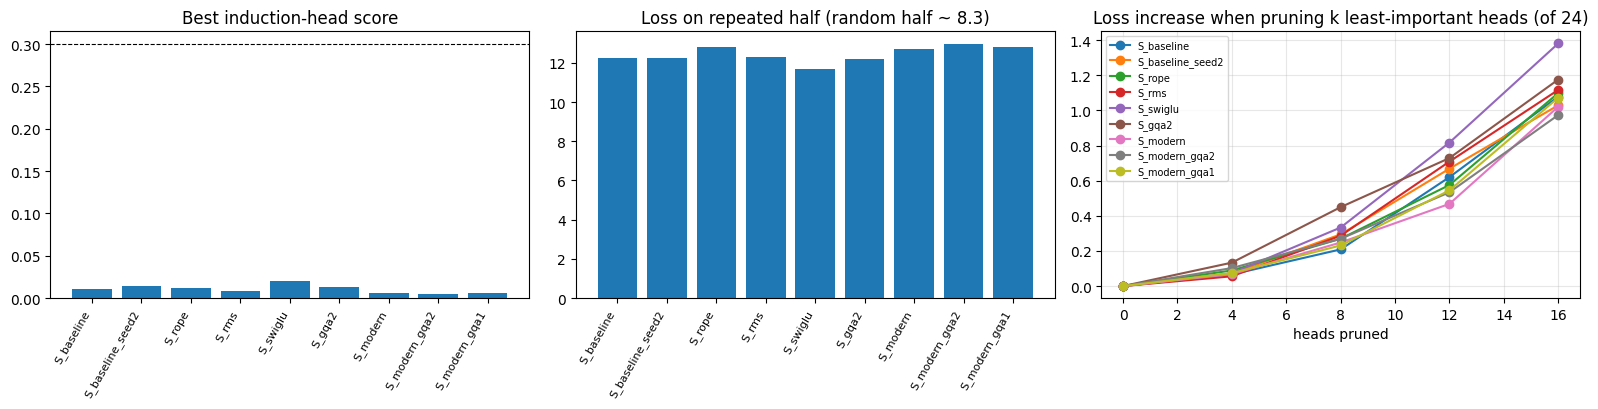

In [ ]:
import sys, importlib, json, numpy as np, pandas as pd, torch, torch.nn.functional as F
import matplotlib.pyplot as plt
ROOT = '/content/drive/MyDrive/afml_slm'
sys.path.insert(0, ROOT)
import slm, trainlib; importlib.reload(slm); importlib.reload(trainlib)
from trainlib import load_model, evaluate, dev, _val

VARS = ["S_baseline", "S_baseline_seed2", "S_rope", "S_rms", "S_swiglu", "S_gqa2",
        "S_modern", "S_modern_gqa2", "S_modern_gqa1"]
T = 256

def set_mask(m, pruned):                      # pruned = list of (layer, head) to zero out
    for b in m.blocks: b.attn.head_mask.fill_(1.0)
    for l, h in pruned: m.blocks[l].attn.head_mask[h] = 0.0

@torch.no_grad()
def attn_entropy(m, n_seq=64):
    arr = torch.from_numpy(_val[:n_seq * T + 1].astype(np.int64))
    x = arr[:n_seq * T].view(n_seq, T).to(dev)
    L, H = m.c.n_layer, m.c.n_head
    norm = torch.log(torch.arange(1, T + 1, device=dev).float()).clamp_min(1e-6)   # max entropy at each position
    ent = torch.zeros(L, H, device=dev); nch = 0
    for b in m.blocks: b.attn.store_attn = True
    for i in range(0, n_seq, 16):
        m(x[i:i + 16]); nch += 1
        for l, b in enumerate(m.blocks):
            a = b.attn.last_attn                                                   # (B,H,T,T)
            h = -(a * torch.log(a.clamp_min(1e-12))).sum(-1) / norm               # (B,H,T) in [0,1]
            ent[l] += h[:, :, 1:].mean(dim=(0, 2))
    for b in m.blocks: b.attn.store_attn = False; b.attn.last_attn = None
    return (ent / nch).cpu().numpy()

@torch.no_grad()
def induction(m, Lr=128, n=64, seed=0):
    g = torch.Generator().manual_seed(seed)
    r = torch.randint(4, m.c.vocab, (n, Lr), generator=g)
    x = torch.cat([r, r], 1).to(dev)                                               # [r | r], length 256
    L, H = m.c.n_layer, m.c.n_head
    score = torch.zeros(L, H, device=dev); lo1 = lo2 = 0.0; nch = 0
    qi = torch.arange(Lr, 2 * Lr - 1, device=dev); ki = qi - Lr + 1               # query in 2nd copy -> token AFTER earlier occurrence
    for b in m.blocks: b.attn.store_attn = True
    for i in range(0, n, 32):
        xb = x[i:i + 32]
        logits = m(xb, full_logits=True)[0]
        ce = F.cross_entropy(logits[:, :-1].float().transpose(1, 2), xb[:, 1:], reduction='none')
        lo1 += ce[:, :Lr - 1].mean().item(); lo2 += ce[:, Lr:].mean().item(); nch += 1
        for l, b in enumerate(m.blocks):
            score[l] += b.attn.last_attn[:, :, qi, ki].mean(dim=(0, 2))
    for b in m.blocks: b.attn.store_attn = False; b.attn.last_attn = None
    return (score / nch).cpu().numpy(), lo1 / nch, lo2 / nch

R = {}
for name in VARS:
    m = load_model(name); L, H = m.c.n_layer, m.c.n_head
    ent = attn_entropy(m)
    base = evaluate(m, T, max_seqs=256)
    delta = np.zeros((L, H))
    for l in range(L):
        for h in range(H):
            set_mask(m, [(l, h)]); delta[l, h] = evaluate(m, T, max_seqs=256) - base
    order = np.argsort(delta.reshape(-1)); prune = {}                              # least important heads first
    for k in [0, 4, 8, 12, 16]:
        set_mask(m, [divmod(int(i), H) for i in order[:k]]); prune[k] = evaluate(m, T, max_seqs=256) - base
    set_mask(m, [])
    ind, lo_rand, lo_rep = induction(m)
    R[name] = dict(ent=ent, delta=delta, prune=prune, ind=ind, lo_rand=lo_rand, lo_rep=lo_rep, base=base)
    print(f"{name}: done")
    del m; torch.cuda.empty_cache()

json.dump({k: {kk: (vv.tolist() if isinstance(vv, np.ndarray) else vv) for kk, vv in v.items()} for k, v in R.items()},
          open(f"{ROOT}/mech_results.json", "w"))

rows = []
for n_, r in R.items():
    rows.append(dict(model=n_, entropy=r['ent'].mean(), dHead_mean=r['delta'].mean(), dHead_max=r['delta'].max(),
                     n_dispensable=int((r['delta'] < 0.01).sum()), prune8=r['prune'][8], prune12=r['prune'][12],
                     best_ind=r['ind'].max(), best_ind_layer=int(np.unravel_index(r['ind'].argmax(), r['ind'].shape)[0]),
                     n_ind_heads=int((r['ind'] > 0.3).sum()), loss_random_half=r['lo_rand'], loss_repeat_half=r['lo_rep']))
df = pd.DataFrame(rows).set_index("model"); df.to_csv(f"{ROOT}/mech_summary.csv")
print("\n", df.round(3).to_string())
print("\nMean normalised attention entropy per layer (0 = peaked, 1 = uniform):")
print(pd.DataFrame({n_: r['ent'].mean(1) for n_, r in R.items()}).T.round(3).to_string())

fig, ax = plt.subplots(1, 3, figsize=(16, 4.2)); names = list(R)
ax[0].bar(range(len(names)), [R[n_]['ind'].max() for n_ in names]); ax[0].set_title("Best induction-head score"); ax[0].axhline(0.3, ls='--', c='k', lw=.8)
ax[1].bar(range(len(names)), [R[n_]['lo_rep'] for n_ in names]); ax[1].set_title("Loss on repeated half (random half ~ 8.3)")
for a in ax[:2]: a.set_xticks(range(len(names))); a.set_xticklabels(names, rotation=60, ha='right', fontsize=8)
for n_ in names: ax[2].plot(list(R[n_]['prune']), list(R[n_]['prune'].values()), marker='o', label=n_)
ax[2].set_title("Loss increase when pruning k least-important heads (of 24)"); ax[2].set_xlabel("heads pruned"); ax[2].legend(fontsize=7); ax[2].grid(alpha=.3)
plt.tight_layout(); plt.savefig(f"{ROOT}/mech.png", dpi=150); plt.show()

In [ ]:
import sys, importlib, numpy as np, pandas as pd, torch, torch.nn.functional as F
ROOT = '/content/drive/MyDrive/afml_slm'
sys.path.insert(0, ROOT)
import slm, trainlib; importlib.reload(slm); importlib.reload(trainlib)
from trainlib import load_model, dev, _val

@torch.no_grad()
def repeat_test(m, first, bs=32):
    """input [first | first]; returns loss on 1st half, loss on 2nd half, best induction-head score"""
    n, Lr = first.shape; x = torch.cat([first, first], 1).to(dev)
    L, H = m.c.n_layer, m.c.n_head
    qi = torch.arange(Lr, 2 * Lr - 1, device=dev); ki = qi - Lr + 1
    score = torch.zeros(L, H, device=dev); l1 = l2 = 0.0; nb = 0
    for b in m.blocks: b.attn.store_attn = True
    for i in range(0, n, bs):
        xb = x[i:i + bs]
        logits = m(xb, full_logits=True)[0]
        ce = F.cross_entropy(logits[:, :-1].float().transpose(1, 2), xb[:, 1:], reduction='none')
        l1 += ce[:, :Lr - 1].mean().item(); l2 += ce[:, Lr:].mean().item(); nb += 1
        for l, b in enumerate(m.blocks):
            score[l] += b.attn.last_attn[:, :, qi, ki].mean(dim=(0, 2))
    for b in m.blocks: b.attn.store_attn = False; b.attn.last_attn = None
    return l1 / nb, l2 / nb, (score / nb).max().item()

g = torch.Generator().manual_seed(0)
rand_first = torch.randint(4, 4096, (64, 128), generator=g)
ix = torch.randint(0, len(_val) - 130, (64,), generator=g).numpy()
nat_first = torch.from_numpy(_val[ix[:, None] + np.arange(128)[None, :]].astype(np.int64))

rows = []
for name in ["S_baseline", "S_modern", "M_baseline", "M_rope", "M_swiglu", "M_modern", "M_base", "L_baseline", "L_modern"]:
    m = load_model(name)
    n1, n2, ind_n = repeat_test(m, nat_first)
    r1, r2, ind_r = repeat_test(m, rand_first)
    rows.append(dict(model=name, params_M=m.n_params()/1e6, nat_1st=n1, nat_2nd=n2, nat_drop=n1 - n2,
                     rand_1st=r1, rand_2nd=r2, rand_drop=r1 - r2, best_ind_random=ind_r, best_ind_natural=ind_n))
    del m; torch.cuda.empty_cache()
df = pd.DataFrame(rows).set_index("model"); df.to_csv(f"{ROOT}/induction_check.csv")
print(df.round(3).to_string())

            params_M  nat_1st  nat_2nd  nat_drop  rand_1st  rand_2nd  rand_drop  best_ind_random  best_ind_natural
model                                                                                                             
S_baseline     5.839    2.128    2.091     0.037    12.476    12.233      0.244            0.011             0.040
S_modern       5.869    2.019    2.026    -0.008    12.948    12.710      0.238            0.006             0.015
M_baseline    15.840    2.024    1.974     0.049    12.125    11.866      0.259            0.011             0.037
M_rope        15.742    1.969    1.939     0.030    12.432    12.164      0.268            0.020             0.045
M_swiglu      15.840    1.985    1.948     0.037    12.309    11.682      0.626            0.021             0.054
M_modern      15.735    1.940    1.945    -0.005    12.604    12.300      0.304            0.009             0.027
M_base        15.735    1.965    1.909     0.056    12.053    10.860      1.193 

## 12. Local LLM judge and win rates

Qwen2.5-7B-Instruct (4-bit), every comparison judged in both orders; the debiased margin removes position bias. Two sanity gates (SFT must beat base, the reference answer must beat SFT) must pass before the judge is used.

In [ ]:
%%writefile /content/drive/MyDrive/afml_slm/judgelib.py
import json, time, numpy as np, pandas as pd, torch
from transformers import AutoTokenizer, AutoModelForCausalLM, BitsAndBytesConfig

SYSTEM = ("You are a strict, impartial evaluator. You compare two responses written by very small language models "
          "to an instruction. Prefer the response that better follows the instruction, is more correct and relevant, "
          "and is more fluent. Gibberish or off-topic text is always worse than a coherent attempt. "
          "Do not prefer a response just because it is longer or comes first. "
          "Both may be poor; still pick the better one. Reply with exactly one letter: A or B.")

def clip(s, n=700):
    s = (s or "").strip()
    return s[:n] if s else "(empty response)"

def build(instruction, reference, ra, rb):
    return (f"Instruction:\n{instruction}\n\nReference answer (good but not the only valid one):\n{reference[:600]}\n\n"
            f"[Response A]\n{clip(ra)}\n\n[Response B]\n{clip(rb)}\n\n"
            "Which response is better? Reply with exactly one letter: A or B.")

class LocalJudge:
    def __init__(self, name="Qwen/Qwen2.5-7B-Instruct", quant4=True):
        self.tok = AutoTokenizer.from_pretrained(name, padding_side="left")
        if quant4:
            kw = dict(quantization_config=BitsAndBytesConfig(load_in_4bit=True, bnb_4bit_quant_type="nf4",
                                                             bnb_4bit_compute_dtype=torch.float16), device_map={"": 0})
        else:
            kw = dict(dtype=torch.float16, device_map={"": 0})
        self.lm = AutoModelForCausalLM.from_pretrained(name, **kw).eval()
        self.idA = self.tok.encode("A", add_special_tokens=False)[0]
        self.idB = self.tok.encode("B", add_special_tokens=False)[0]

    @torch.no_grad()
    def _batch(self, idx, texts):
        enc = self.tok([texts[i] for i in idx], return_tensors="pt", padding=True).to("cuda")
        try:
            try: lg = self.lm(**enc, logits_to_keep=1).logits[:, -1].float()
            except TypeError: lg = self.lm(**enc).logits[:, -1].float()
        except torch.cuda.OutOfMemoryError:
            del enc; torch.cuda.empty_cache()
            if len(idx) == 1: raise
            h = len(idx) // 2
            return self._batch(idx[:h], texts) + self._batch(idx[h:], texts)
        return (lg[:, self.idA] - lg[:, self.idB]).tolist()

    def margins(self, msgs, bs=8):
        """logit(A) - logit(B) per message; positive = judge prefers the response shown first"""
        texts = [self.tok.apply_chat_template([{"role": "system", "content": SYSTEM}, {"role": "user", "content": m}],
                                              tokenize=False, add_generation_prompt=True) for m in msgs]
        order = sorted(range(len(texts)), key=lambda i: len(texts[i])); out = [0.0] * len(texts)
        for k in range(0, len(order), bs):
            idx = order[k:k + bs]
            for i, v in zip(idx, self._batch(idx, texts)): out[i] = v
        return out

    def free(self):
        del self.lm; torch.cuda.empty_cache()

def run_judgments(judge, keys, make_msg, cache, cache_path, chunk=64):
    todo = [k for k in keys if k not in cache]
    print(f"{len(keys)} judgments needed, {len(todo)} not cached yet")
    t0 = time.time()
    for s in range(0, len(todo), chunk):
        part = todo[s:s + chunk]
        for k, d in zip(part, judge.margins([make_msg(k) for k in part])): cache[k] = d
        if (s // chunk) % 5 == 4 or s + chunk >= len(todo):
            json.dump(cache, open(cache_path, "w")); print(f"  {min(s + chunk, len(todo))}/{len(todo)} ({(time.time()-t0)/60:.1f} min)")

def winrate_table(cache, comps, gens, n, seed=0):
    """debiased: m = (margin[X shown first] - margin[Y shown first]) / 2 ; position bias cancels exactly"""
    rng = np.random.default_rng(seed); rows = []
    for X, Y in comps:
        d1 = np.array([cache[f"{i}|{X}|{Y}"] for i in range(n)]); d2 = np.array([cache[f"{i}|{Y}|{X}"] for i in range(n)])
        m = (d1 - d2) / 2; win = (m > 0).astype(float) + 0.5 * (m == 0)
        boot = [rng.choice(win, n).mean() for _ in range(2000)]
        wX = np.array([len(gens[X][i].split()) for i in range(n)]); wY = np.array([len(gens[Y][i].split()) for i in range(n)]); lng = wX > wY
        rows.append(dict(comparison=f"{X} vs {Y}", win_rate=win.mean(), ci_lo=np.percentile(boot, 2.5), ci_hi=np.percentile(boot, 97.5),
                         mean_margin=m.mean(), order_consistent=np.mean((d1 > 0) == (d2 < 0)),
                         words_X=wX.mean(), words_Y=wY.mean(), corr_margin_vs_len=np.corrcoef(m, wX - wY)[0, 1],
                         win_when_X_longer=win[lng].mean() if lng.any() else np.nan, n_X_longer=int(lng.sum()),
                         win_when_X_not_longer=win[~lng].mean() if (~lng).any() else np.nan))
    return pd.DataFrame(rows).set_index("comparison")

Overwriting /content/drive/MyDrive/afml_slm/judgelib.py


In [ ]:
import sys, os, json, importlib, numpy as np, pandas as pd, torch
ROOT = '/content/drive/MyDrive/afml_slm'
sys.path.insert(0, ROOT)
import judgelib; importlib.reload(judgelib)
from judgelib import LocalJudge, build, run_judgments, winrate_table

JUDGE_MODEL, QUANT4 = "Qwen/Qwen2.5-7B-Instruct", True      # fallback if it won't fit: "Qwen/Qwen2.5-3B-Instruct", False
TAG = JUDGE_MODEL.split("/")[-1]

eval_set = json.load(open(f"{ROOT}/eval_set.json"))
prompts = [e["instruction"].strip() + (("\n" + e["input"].strip()) if e["input"].strip() else "") for e in eval_set]
refs = [e["output"].strip() for e in eval_set]
MODELS = ["M_base", "M_sft", "M_dpo_b0.03_v2", "M_dpo_b0.1_v2", "M_dpo_b0.3_v2", "M_dpo_b1.0_v2", "M_ipo_b0.1_v2", "M_simpo_b2.0_v2"]
gens = {n: json.load(open(f"{ROOT}/gens/{n}.json")) for n in MODELS}
gens["REFERENCE"] = refs                                       # sanity-check opponent
COMPARISONS = ([("M_sft", "M_base"), ("REFERENCE", "M_sft")] + [(m, "M_sft") for m in MODELS[2:]] +
               [("M_dpo_b0.1_v2", "M_simpo_b2.0_v2"), ("M_dpo_b0.1_v2", "M_ipo_b0.1_v2")])

CACHE = f"{ROOT}/judge_cache_margin_{TAG}.json"
cache = json.load(open(CACHE)) if os.path.exists(CACHE) else {}
keys = sorted({f"{i}|{a}|{b}" for X, Y in COMPARISONS for i in range(len(prompts)) for a, b in ((X, Y), (Y, X))})
def msg(k):
    i, a, b = k.split("|"); i = int(i); return build(prompts[i], refs[i], gens[a][i], gens[b][i])

if any(k not in cache for k in keys):
    if 'J' not in globals(): J = LocalJudge(JUDGE_MODEL, QUANT4)     # kept alive for Cell 14
    run_judgments(J, keys, msg, cache, CACHE)

print(f"\nmean A-slot minus B-slot margin = {np.mean(list(cache.values())):+.2f}  (position bias; cancelled by the swap)")
res = winrate_table(cache, COMPARISONS, gens, len(prompts)); res.to_csv(f"{ROOT}/winrates_margin_{TAG}.csv")
print("\n", res.round(3).to_string())
s1, s2 = res.loc["M_sft vs M_base", "win_rate"], res.loc["REFERENCE vs M_sft", "win_rate"]
print(f"\nSANITY  SFT beats base:      {s1:.0%} -> {'PASS' if s1 >= 0.70 else 'FAIL'}")
print(f"SANITY  reference beats SFT: {s2:.0%} -> {'PASS' if s2 >= 0.70 else 'FAIL'}")
if min(s1, s2) < 0.70: print("Judge NOT trustworthy: do not use the DPO rows and do not run Cell 14. Paste me this table.")

3000 judgments needed, 3000 not cached yet
  320/3000 (1.7 min)
  640/3000 (3.4 min)
  960/3000 (5.0 min)
  1280/3000 (6.7 min)
  1600/3000 (8.3 min)
  1920/3000 (10.2 min)
  2240/3000 (11.9 min)
  2560/3000 (13.7 min)
  2880/3000 (15.4 min)
  3000/3000 (16.0 min)

mean A-slot minus B-slot margin = +0.28  (position bias; cancelled by the swap)

                                   win_rate  ci_lo  ci_hi  mean_margin  order_consistent  words_X  words_Y  corr_margin_vs_len  win_when_X_longer  n_X_longer  win_when_X_not_longer
comparison                                                                                                                                                                         
M_sft vs M_base                      0.813  0.747  0.880        4.926             0.627   30.873   45.740              -0.267              0.679          53                  0.887
REFERENCE vs M_sft                   0.970  0.940  0.993       14.022             0.967   44.740   30.873       

## 13. On-policy preference data vs UltraFeedback

Four samples per prompt from our SFT model are ranked by the judge; trained against a size-matched UltraFeedback control. Held-out split by prompt. This cell stops itself if the judge failed its sanity gates.

In [ ]:
import sys, os, json, time, random, hashlib, importlib, numpy as np, pandas as pd, torch
ROOT = '/content/drive/MyDrive/afml_slm'
sys.path.insert(0, ROOT)
import slm, trainlib, alignlib, dpolib, judgelib
for _m in (slm, trainlib, alignlib, dpolib, judgelib): importlib.reload(_m)
from alignlib import *
from dpolib import *
from judgelib import LocalJudge, build, run_judgments, winrate_table
from trainlib import evaluate

JUDGE_MODEL, QUANT4 = "Qwen/Qwen2.5-7B-Instruct", True         # must match Cell 13
JTAG = JUDGE_MODEL.split("/")[-1]
N_PROMPTS, KEEP_FRAC, TEST_FRAC, BETA, EPOCHS = 500, 0.75, 0.2, 0.1, 3
PAIR_IDX = [(0, 1), (2, 3), (0, 2), (1, 3)]                    # 4 pairs per prompt, each response used twice
h8 = lambda obj: hashlib.md5(json.dumps(obj).encode()).hexdigest()[:8]
os.makedirs(f"{ROOT}/onpolicy", exist_ok=True)

# ---- gate: the judge must have passed Cell 13's sanity checks ----
csv = f"{ROOT}/winrates_margin_{JTAG}.csv"
assert os.path.exists(csv), "Run Cell 13 first."
chk = pd.read_csv(csv, index_col=0)
s1, s2 = chk.loc["M_sft vs M_base", "win_rate"], chk.loc["REFERENCE vs M_sft", "win_rate"]
assert min(s1, s2) >= 0.70, f"Judge failed sanity ({s1:.0%}, {s2:.0%}); do not continue."
print(f"judge sanity OK: SFT>base {s1:.0%}, reference>SFT {s2:.0%}")

# ---- 1) prompts + cached on-policy samples (same selection code as before, so indices line up) ----
train_ex, _, _ = alpaca_splits(seed=0)
selected = random.Random(42).sample(train_ex, min(N_PROMPTS, len(train_ex)))
keep = [i for i, e in enumerate(selected) if len(tok.encode(prompt_text(e)).ids) <= 100]
prompts = [prompt_text(selected[i]) for i in keep]; refs = [selected[i]["output"].strip() for i in keep]
GEN_FILE = f"{ROOT}/onpolicy/sft_responses.json"
if os.path.exists(GEN_FILE):
    responses = json.load(open(GEN_FILE))
else:
    sft = load_ckpt("M_sft"); responses = [[] for _ in prompts]; t0 = time.time()
    for s in range(4):
        for i, o in enumerate(gen_responses(sft, prompts, chat=True, max_new=100, temperature=0.8, top_k=40, seed=s + 10)):
            responses[i].append(o)
        json.dump(responses, open(GEN_FILE, "w")); print(f"generation {s+1}/4 ({(time.time()-t0)/60:.1f} min)")
    del sft; torch.cuda.empty_cache()
assert len(responses) == len(prompts) and all(len(r) == 4 for r in responses), "cached responses don't match prompt list"
print(f"{len(prompts)} prompts x 4 on-policy SFT samples")

# ---- 2) judge pairs in both orders (margins cached) ----
if 'J' not in globals(): J = LocalJudge(JUDGE_MODEL, QUANT4)
OCACHE = f"{ROOT}/onpolicy/judge_margin_{JTAG}.json"
ocache = json.load(open(OCACHE)) if os.path.exists(OCACHE) else {}
okeys = [f"{i}|{a}|{b}" for i in range(len(prompts)) for x, y in PAIR_IDX for a, b in ((x, y), (y, x))]
def omsg(k):
    i, a, b = map(int, k.split("|")); return build(prompts[i], refs[i], responses[i][a], responses[i][b])
run_judgments(J, okeys, omsg, ocache, OCACHE)

# ---- 3) keep order-consistent, confident pairs; split by PROMPT into train / held-out test ----
cand = []
for i in range(len(prompts)):
    for a, b in PAIR_IDX:
        d1, d2 = ocache[f"{i}|{a}|{b}"], ocache[f"{i}|{b}|{a}"]
        cand.append(dict(i=i, a=a, b=b, m=(d1 - d2) / 2, ok=bool((d1 > 0) == (d2 < 0))))
cons = [c for c in cand if c["ok"]]
thr = np.quantile([abs(c["m"]) for c in cons], 1 - KEEP_FRAC)
kept = [c for c in cons if abs(c["m"]) >= thr]
print(f"candidate pairs {len(cand)} | order-consistent {len(cons)} ({len(cons)/len(cand):.0%}) | kept (top {KEEP_FRAC:.0%} by margin) {len(kept)}")

ids = list(range(len(prompts))); random.Random(1).shuffle(ids); test_ids = set(ids[:int(TEST_FRAC * len(ids))])
train_pairs, test_pairs = [], []
for c in kept:
    w, l = (c["a"], c["b"]) if c["m"] > 0 else (c["b"], c["a"]); i = c["i"]
    if responses[i][w].strip() == responses[i][l].strip(): continue
    p = [USER] + tok.encode(prompts[i]).ids + [ASSIST]
    if len(p) > 160: continue
    mx = 256 - len(p); ch = (tok.encode(responses[i][w]).ids + [EOT])[:mx]; rj = (tok.encode(responses[i][l]).ids + [EOT])[:mx]
    if len(ch) <= 1 or len(rj) <= 1: continue
    (test_pairs if i in test_ids else train_pairs).append((p, ch, rj))
json.dump(train_pairs, open(f"{ROOT}/onpolicy/onp_v2_train.json", "w")); json.dump(test_pairs, open(f"{ROOT}/onpolicy/onp_v2_test.json", "w"))
lc = np.array([len(p[1]) for p in train_pairs]); lr_ = np.array([len(p[2]) for p in train_pairs])
print(f"train pairs {len(train_pairs)} | held-out test pairs {len(test_pairs)}")
print(f"on-policy chosen {lc.mean():.0f} vs rejected {lr_.mean():.0f} tokens | chosen longer in {np.mean(lc > lr_):.0%} of pairs (judge's length bias)")
assert len(train_pairs) >= 64, "too few pairs; raise KEEP_FRAC or check the judge"

# ---- 4) train: on-policy DPO vs a size-matched UltraFeedback control (same pairs / beta / epochs / steps) ----
NAME_ONP = f"M_dpo_onp_{h8(train_pairs)}"
dpo_train(NAME_ONP, train_pairs, "onpv2_" + h8(train_pairs), loss="dpo", beta=BETA, epochs=EPOCHS)
uf_all = json.load(open(f"{ROOT}/pairs2_train_prefs.json"))
uf_sub = random.Random(0).sample(uf_all, len(train_pairs)); NAME_UFM = f"M_dpo_ufm_{len(uf_sub)}"
dpo_train(NAME_UFM, uf_sub, "ufm_" + h8(uf_sub), loss="dpo", beta=BETA, epochs=EPOCHS)

# ---- 5) held-out accuracy on BOTH test sets + alignment tax ----
uf_test = json.load(open(f"{ROOT}/pairs2_test_prefs.json"))
ref_uf = get_ref("M_sft", uf_test, "ufv2_test"); ref_onp = get_ref("M_sft", test_pairs, "onpv2test_" + h8(test_pairs))
fw_va = np.fromfile(f"{ROOT}/fw_val.bin", dtype=np.uint16); _, val_ex, _ = alpaca_splits(); val_d = encode_sft(val_ex)
ci = lambda p, n: f"{p:.1%} ±{1.96*np.sqrt(p*(1-p)/n):.1%}"
rows = []
for name in ["M_sft", "M_dpo_b0.1_v2", NAME_UFM, NAME_ONP]:
    m = load_ckpt(name)
    r = dict(model=name, alpaca_nll=sft_val_loss(m, val_d), tinystories=evaluate(m, 256, max_seqs=300),
             fineweb=evaluate(m, 256, max_seqs=300, data=fw_va))
    if name != "M_sft":      # SFT vs itself is 0 by construction, so it is left blank
        r[f"acc_UF_test(n={len(uf_test)})"] = ci(pref_acc(m, uf_test, ref_uf), len(uf_test))
        r[f"acc_onpolicy_test(n={len(test_pairs)})"] = ci(pref_acc(m, test_pairs, ref_onp), len(test_pairs))
    rows.append(r); del m; torch.cuda.empty_cache()
ev = pd.DataFrame(rows).set_index("model"); ev.to_csv(f"{ROOT}/onpolicy_v2_eval.csv")
print("\nHELD-OUT accuracy + alignment tax (95% CI):\n", ev.round(3).to_string())

# ---- 6) generate on the 150 fixed eval prompts ----
eval_set = json.load(open(f"{ROOT}/eval_set.json"))
eprompts = [prompt_text(e) for e in eval_set]; erefs = [e["output"].strip() for e in eval_set]
for name in [NAME_UFM, NAME_ONP]:
    pth = f"{ROOT}/gens/{name}.json"
    if not os.path.exists(pth): json.dump(gen_responses(load_ckpt(name), eprompts, chat=True), open(pth, "w"))
egens = {n: json.load(open(f"{ROOT}/gens/{n}.json")) for n in ["M_sft", "M_dpo_b0.1_v2", NAME_UFM, NAME_ONP]}
print("\navg words/response:", {n: round(float(np.mean([len(x.split()) for x in g])), 1) for n, g in egens.items()})

# ---- 7) judged win rates (same debiased judge, same cache as Cell 13) ----
JC = f"{ROOT}/judge_cache_margin_{JTAG}.json"; jc = json.load(open(JC)) if os.path.exists(JC) else {}
COMPS = [(NAME_ONP, "M_sft"), (NAME_UFM, "M_sft"), (NAME_ONP, NAME_UFM), (NAME_ONP, "M_dpo_b0.1_v2")]
ekeys = sorted({f"{i}|{a}|{b}" for X, Y in COMPS for i in range(len(eprompts)) for a, b in ((X, Y), (Y, X))})
def emsg(k):
    i, a, b = k.split("|"); i = int(i); return build(eprompts[i], erefs[i], egens[a][i], egens[b][i])
run_judgments(J, ekeys, emsg, jc, JC)
wr = winrate_table(jc, COMPS, egens, len(eprompts)); wr.to_csv(f"{ROOT}/onpolicy_v2_winrates_{JTAG}.csv")
print("\nJUDGED WIN RATES (150 held-out prompts, both orders):\n", wr.round(3).to_string())
J.free(); del J
print("\nCELL 14 COMPLETE")

judge sanity OK: SFT>base 81%, reference>SFT 97%


489 prompts x 4 on-policy SFT samples
3912 judgments needed, 3912 not cached yet
  320/3912 (1.7 min)
  640/3912 (3.3 min)
  960/3912 (5.1 min)
  1280/3912 (6.7 min)
  1600/3912 (8.2 min)
  1920/3912 (9.8 min)
  2240/3912 (11.4 min)
  2560/3912 (13.2 min)
  2880/3912 (14.9 min)
  3200/3912 (16.6 min)
  3520/3912 (18.2 min)
  3840/3912 (19.8 min)
  3912/3912 (20.2 min)
candidate pairs 1956 | order-consistent 999 (51%) | kept (top 75% by margin) 752
train pairs 612 | held-out test pairs 140
on-policy chosen 42 vs rejected 50 tokens | chosen longer in 36% of pairs (judge's length bias)
[M_dpo_onp_e44c8e5d] loss=dpo beta=0.1 lr=2e-05 pairs=612 steps=57
[M_dpo_onp_e44c8e5d] 50/57 loss 0.430 acc 0.86 margin 0.94 dlogp chosen +2.3 rejected -7.0 | 0.1 min
[M_dpo_onp_e44c8e5d] 57/57 loss 0.236 acc 1.00 margin 1.82 dlogp chosen +4.2 rejected -14.0 | 0.1 min
[M_dpo_ufm_612] loss=dpo beta=0.1 lr=2e-05 pairs=612 steps=57
[M_dpo_ufm_612] 50/57 loss 0.398 acc 0.81 margin 1.18 dlogp chosen +6.1 reject

## 14. Report figures and results folder

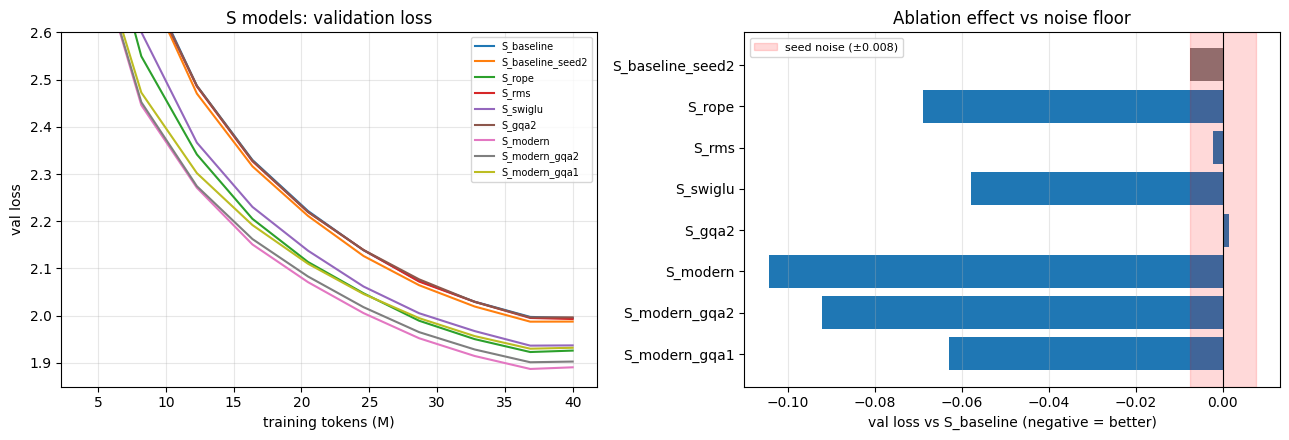

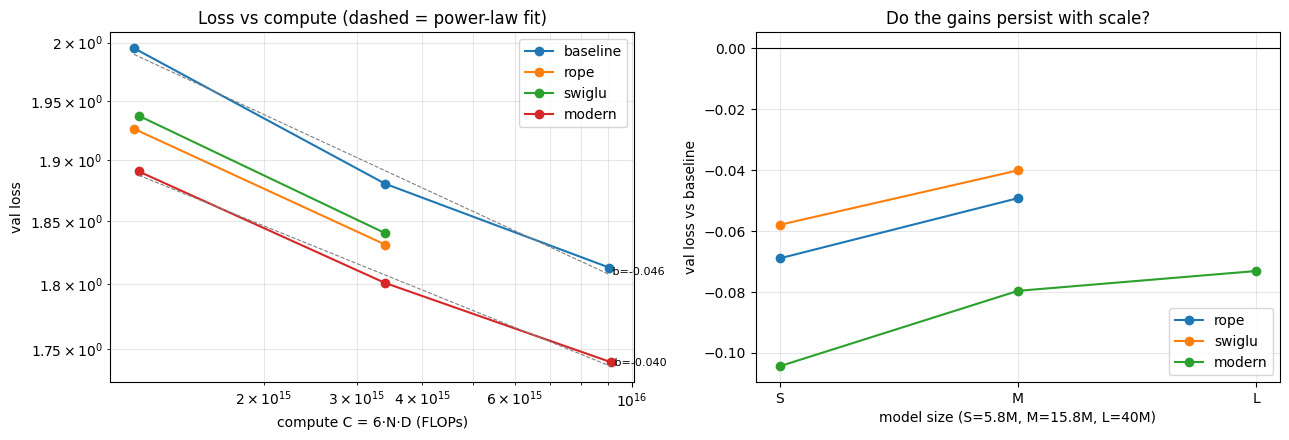

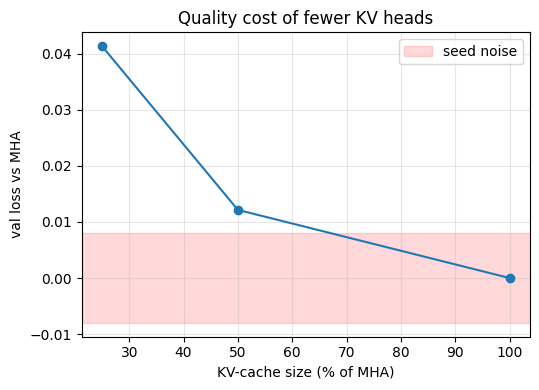

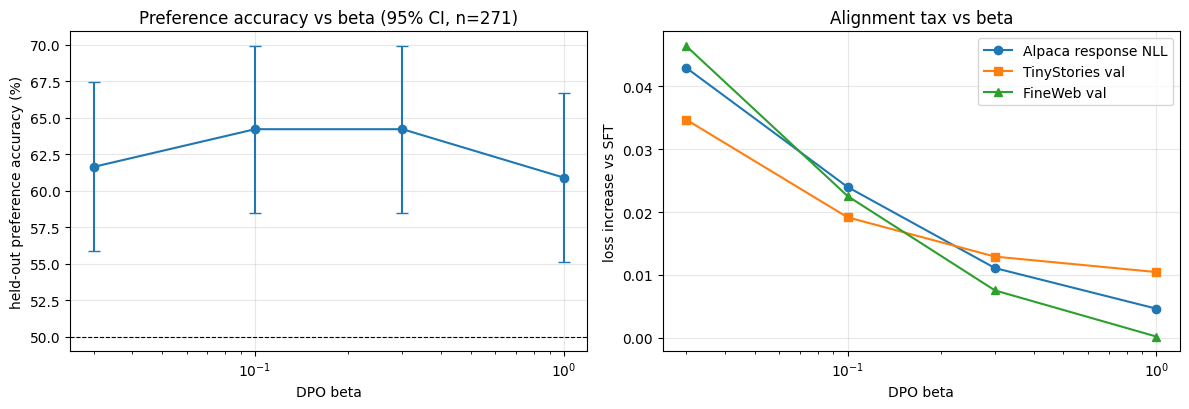

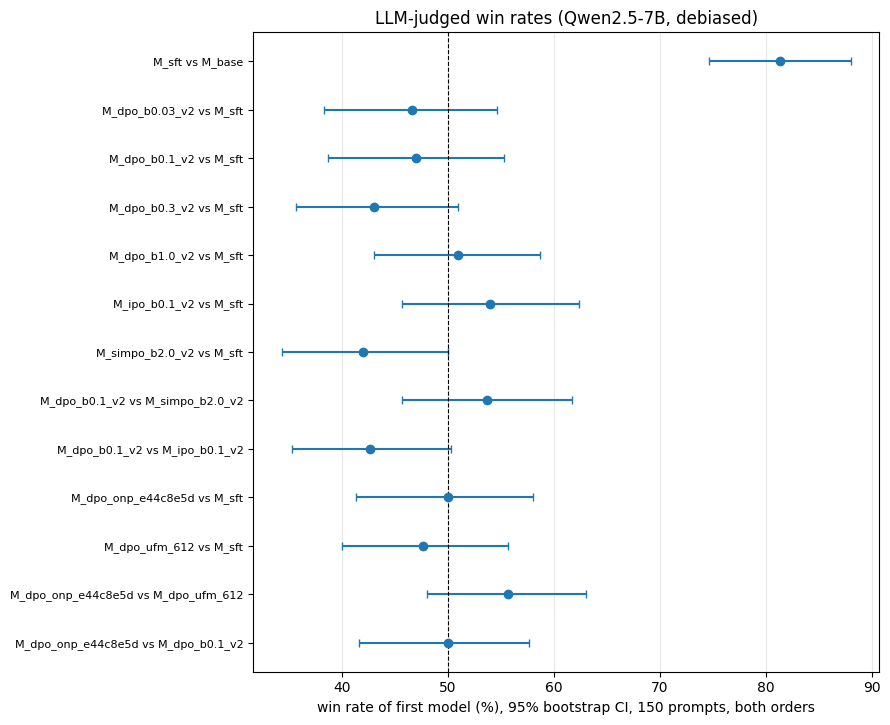


collected 58 files -> /content/drive/MyDrive/afml_slm/report_assets
zip for download: /content/drive/MyDrive/afml_slm/report_assets.zip
   ablation_S.csv
   dpo_sweep.csv
   eval_set.json
   figs/fig_ablation_S.png
   figs/fig_dpo_beta.png
   figs/fig_gqa_quality.png
   figs/fig_scaling.png
   figs/fig_winrates.png
   gens/M_base.json
   gens/M_dpo_b0.03_v2.json
   gens/M_dpo_b0.1.json
   gens/M_dpo_b0.1_v2.json
   gens/M_dpo_b0.3_v2.json
   gens/M_dpo_b1.0_v2.json
   gens/M_dpo_onp_e44c8e5d.json
   gens/M_dpo_ufm_612.json
   gens/M_ipo_b0.1_v2.json
   gens/M_sft.json
   gens/M_simpo_b2.0_v2.json
   gqa_quality.csv
   induction_check.csv
   kv_bench.csv
   kv_bench.png
   kv_bench_v2.csv
   kv_cache_speedup.csv
   length_gen.csv
   length_gen.png
   mech.png
   mech_results.json
   mech_summary.csv
   onpolicy_v2_eval.csv
   onpolicy_v2_winrates_Qwen2.5-7B-Instruct.csv
   runs/L_baseline.json
   runs/L_modern.json
   runs/M_baseline.json
   runs/M_dpo_b0.03_v2.json
   runs/M_dpo_b0.1.

In [ ]:
import os, json, glob, shutil, numpy as np, pandas as pd
import matplotlib.pyplot as plt
from google.colab import drive
if not os.path.isdir('/content/drive/MyDrive'): drive.mount('/content/drive')
ROOT = '/content/drive/MyDrive/afml_slm'; OUT = f"{ROOT}/figs"; os.makedirs(OUT, exist_ok=True)
runs = {os.path.basename(f)[:-5]: json.load(open(f)) for f in glob.glob(f"{ROOT}/runs/*.json")}
def safe(fn):
    try: fn()
    except Exception as e: print(f"[skipped {fn.__name__}] {type(e).__name__}: {e}")

def fig_ablation():
    S = ["S_baseline", "S_baseline_seed2", "S_rope", "S_rms", "S_swiglu", "S_gqa2", "S_modern", "S_modern_gqa2", "S_modern_gqa1"]
    fig, ax = plt.subplots(1, 2, figsize=(13, 4.5))
    for n in S:
        c = runs[n]['curve']; ax[0].plot([p['tokens'] / 1e6 for p in c], [p['val_loss'] for p in c], label=n, lw=1.5)
    ax[0].set_ylim(1.85, 2.6); ax[0].set_xlabel("training tokens (M)"); ax[0].set_ylabel("val loss"); ax[0].set_title("S models: validation loss")
    ax[0].legend(fontsize=7); ax[0].grid(alpha=.3)
    base = runs["S_baseline"]['val_loss']; noise = abs(runs["S_baseline_seed2"]['val_loss'] - base)
    names = [n for n in S if n != "S_baseline"]
    ax[1].barh(names, [runs[n]['val_loss'] - base for n in names], color=["gray" if n == "S_baseline_seed2" else "tab:blue" for n in names])
    ax[1].axvspan(-noise, noise, color="red", alpha=.15, label=f"seed noise (±{noise:.3f})"); ax[1].axvline(0, c="k", lw=.8)
    ax[1].set_xlabel("val loss vs S_baseline (negative = better)"); ax[1].set_title("Ablation effect vs noise floor")
    ax[1].invert_yaxis(); ax[1].legend(fontsize=8); ax[1].grid(alpha=.3, axis="x")
    plt.tight_layout(); plt.savefig(f"{OUT}/fig_ablation_S.png", dpi=150); plt.show()

def fig_scaling():
    sc = pd.read_csv(f"{ROOT}/scaling.csv"); fig, ax = plt.subplots(1, 2, figsize=(13, 4.5))
    for var in ["baseline", "rope", "swiglu", "modern"]:
        dd = sc[sc.variant == var].sort_values("flops"); ax[0].loglog(dd.flops, dd.val_loss, "o-", label=var)
        if len(dd) >= 3:
            b, a = np.polyfit(np.log(dd.flops), np.log(dd.val_loss), 1)
            xs = np.logspace(np.log10(dd.flops.min()), np.log10(dd.flops.max()), 50)
            ax[0].loglog(xs, np.exp(a) * xs ** b, "--", c="gray", lw=.8); ax[0].text(xs[-1], np.exp(a) * xs[-1] ** b, f" b={b:.3f}", fontsize=8)
    ax[0].set_xlabel("compute C = 6·N·D (FLOPs)"); ax[0].set_ylabel("val loss"); ax[0].set_title("Loss vs compute (dashed = power-law fit)")
    ax[0].legend(); ax[0].grid(alpha=.3, which="both")
    piv = sc.pivot(index="variant", columns="size", values="val_loss")[["S", "M", "L"]]
    for var in ["rope", "swiglu", "modern"]:
        dl = (piv.loc[var] - piv.loc["baseline"]).dropna(); ax[1].plot(dl.index, dl.values, "o-", label=var)
    ax[1].axhline(0, c="k", lw=.8); ax[1].set_xlabel("model size (S=5.8M, M=15.8M, L=40M)"); ax[1].set_ylabel("val loss vs baseline")
    ax[1].set_title("Do the gains persist with scale?"); ax[1].legend(); ax[1].grid(alpha=.3)
    plt.tight_layout(); plt.savefig(f"{OUT}/fig_scaling.png", dpi=150); plt.show()

def fig_gqa():
    g = pd.read_csv(f"{ROOT}/gqa_quality.csv"); plt.figure(figsize=(5.5, 4))
    plt.plot(g.kv_heads / 4 * 100, g.d_loss_vs_MHA, "o-"); plt.axhspan(-0.008, 0.008, color="red", alpha=.15, label="seed noise")
    plt.xlabel("KV-cache size (% of MHA)"); plt.ylabel("val loss vs MHA"); plt.title("Quality cost of fewer KV heads")
    plt.legend(); plt.grid(alpha=.3); plt.tight_layout(); plt.savefig(f"{OUT}/fig_gqa_quality.png", dpi=150); plt.show()

def fig_dpo_beta():
    d = pd.read_csv(f"{ROOT}/dpo_sweep.csv", index_col=0)
    dd = d[d.index.str.startswith("M_dpo_b") & d.index.str.endswith("_v2")].copy()
    dd["beta"] = [float(i.split("_b")[1].split("_")[0]) for i in dd.index]; dd = dd.sort_values("beta")
    se = np.sqrt(dd.heldout_pref_acc * (1 - dd.heldout_pref_acc) / 271); sft = d.loc["M_sft"]
    fig, ax = plt.subplots(1, 2, figsize=(12, 4.2))
    ax[0].errorbar(dd.beta, dd.heldout_pref_acc * 100, yerr=1.96 * se * 100, fmt="o-", capsize=4); ax[0].axhline(50, c="k", ls="--", lw=.8)
    ax[0].set_xscale("log"); ax[0].set_xlabel("DPO beta"); ax[0].set_ylabel("held-out preference accuracy (%)")
    ax[0].set_title("Preference accuracy vs beta (95% CI, n=271)"); ax[0].grid(alpha=.3)
    for col, lab, mk in [("alpaca_nll", "Alpaca response NLL", "o-"), ("tinystories", "TinyStories val", "s-"), ("fineweb", "FineWeb val", "^-")]:
        ax[1].plot(dd.beta, dd[col] - sft[col], mk, label=lab)
    ax[1].set_xscale("log"); ax[1].set_xlabel("DPO beta"); ax[1].set_ylabel("loss increase vs SFT"); ax[1].set_title("Alignment tax vs beta")
    ax[1].legend(); ax[1].grid(alpha=.3); plt.tight_layout(); plt.savefig(f"{OUT}/fig_dpo_beta.png", dpi=150); plt.show()

def fig_winrates():
    fs = sorted(glob.glob(f"{ROOT}/winrates_margin_*.csv")); assert fs, "no judge results yet"
    parts = [pd.read_csv(f, index_col=0) for f in fs + glob.glob(f"{ROOT}/onpolicy_v2_winrates_*.csv")]
    w = pd.concat(parts); w = w[~w.index.str.startswith("REFERENCE")]; w = w[~w.index.duplicated()]
    plt.figure(figsize=(9, 0.45 * len(w) + 1.5)); y = np.arange(len(w))
    plt.errorbar(w.win_rate * 100, y, xerr=[(w.win_rate - w.ci_lo) * 100, (w.ci_hi - w.win_rate) * 100], fmt="o", capsize=3)
    plt.axvline(50, c="k", ls="--", lw=.8); plt.yticks(y, w.index, fontsize=8); plt.gca().invert_yaxis()
    plt.xlabel("win rate of first model (%), 95% bootstrap CI, 150 prompts, both orders"); plt.title("LLM-judged win rates (Qwen2.5-7B, debiased)")
    plt.grid(alpha=.3, axis="x"); plt.tight_layout(); plt.savefig(f"{OUT}/fig_winrates.png", dpi=150); plt.show()

for f in (fig_ablation, fig_scaling, fig_gqa, fig_dpo_beta, fig_winrates): safe(f)

# ---------------- collect everything into a CLEAN report_assets (old one is wiped: it held the invalid judge/on-policy files) ----------------
OUTR = f"{ROOT}/report_assets"
if os.path.exists(OUTR): shutil.rmtree(OUTR)
os.makedirs(OUTR)
SKIP_DIRS = {'ckpt', 'report_assets', '__pycache__', '.ipynb_checkpoints'}
SKIP_NAME = ('judge_cache', 'judge_margin', 'pairs', 'ref_', 'sft_responses', 'tokenizer', 'winrates_local',
             'onpolicy_comparison', 'onpolicy_pairs', 'onp_v2_')
manifest = []
for src in sorted((ROOT if isinstance(ROOT, str) else str(ROOT)) and glob.glob(f"{ROOT}/**/*", recursive=True)):
    rel = os.path.relpath(src, ROOT)
    if not os.path.isfile(src) or any(p in SKIP_DIRS for p in rel.split(os.sep)): continue
    if os.path.splitext(src)[1].lower() not in {'.csv', '.png', '.json'} or any(s in os.path.basename(src) for s in SKIP_NAME): continue
    dst = os.path.join(OUTR, rel); os.makedirs(os.path.dirname(dst), exist_ok=True); shutil.copy2(src, dst); manifest.append(rel)
json.dump(manifest, open(f"{OUTR}/manifest.json", "w"), indent=1)
zp = shutil.make_archive(f"{ROOT}/report_assets", "zip", OUTR)
print(f"\ncollected {len(manifest)} files -> {OUTR}\nzip for download: {zp}")
for m in manifest: print("  ", m)

## 15. Blind manual review

30 random evaluation prompts; three shuffled responses each (SFT, UltraFeedback DPO, on-policy DPO). The key is stored separately from the sheet given to raters.

In [ ]:
import json, random, pandas as pd
ROOT = '/content/drive/MyDrive/afml_slm'
es = json.load(open(f"{ROOT}/eval_set.json"))
names = ["M_sft", "M_dpo_b0.1_v2", "M_dpo_onp_e44c8e5d"]
g = {n: json.load(open(f"{ROOT}/gens/{n}.json")) for n in names}
rows = []
for i in random.Random(0).sample(range(len(es)), 30):
    p = es[i]["instruction"].strip() + (("\n" + es[i]["input"].strip()) if es[i]["input"].strip() else "")
    order = names[:]; random.Random(i).shuffle(order)
    row = {"id": i, "prompt": p[:300], "reference": es[i]["output"][:300]}
    for k, n in enumerate(order): row[f"resp_{'ABC'[k]}"] = g[n][i][:400]
    for L in "ABC": row[f"score_{L}"] = ""
    row["key"] = ",".join(order)             # hide this column from raters
    rows.append(row)
pd.DataFrame(rows).to_csv(f"{ROOT}/manual_review_blind.csv", index=False)
print("saved manual_review_blind.csv  (score 0 = wrong or gibberish, 1 = partly relevant, 2 = follows the instruction)")

saved manual_review_blind.csv  (score 0 = wrong or gibberish, 1 = partly relevant, 2 = follows the instruction)


In [ ]:
import pandas as pd
ROOT = '/content/drive/MyDrive/afml_slm'
df = pd.read_csv(f"{ROOT}/manual_review_blind.csv")
df[["id", "key"]].to_csv(f"{ROOT}/manual_review_key.csv", index=False)           # keep private
df.drop(columns=["key"]).to_csv(f"{ROOT}/manual_review_raters.csv", index=False)  # give this one out
print("rater file:", f"{ROOT}/manual_review_raters.csv")

rater file: /content/drive/MyDrive/afml_slm/manual_review_raters.csv


In [ ]:
import glob, numpy as np, pandas as pd
ROOT = '/content/drive/MyDrive/afml_slm'
key = pd.read_csv(f"{ROOT}/manual_review_key.csv").set_index("id")["key"]
files = sorted(glob.glob(f"{ROOT}/scored_*.csv")) + sorted(glob.glob(f"{ROOT}/scored_*.xlsx"))   # one file per rater
print("score files:", [f.split('/')[-1] for f in files])
rec = []
for f in files:
    d = pd.read_csv(f) if f.endswith(".csv") else pd.read_excel(f); rater = f.split("scored_")[-1].rsplit(".", 1)[0]
    for _, r in d.iterrows():
        for k, n in enumerate(key[r["id"]].split(",")):
            s = r[f"score_{'ABC'[k]}"]
            if pd.notna(s): rec.append(dict(rater=rater, id=r["id"], model=n, position="ABC"[k], score=float(s)))
R = pd.DataFrame(rec); assert len(R), "no scores found"
pp = R.groupby(["id", "model"])["score"].mean().unstack()          # average raters per prompt
rng = np.random.default_rng(0); out = []
for m in pp.columns:
    v = pp[m].dropna().values; boot = [rng.choice(v, len(v)).mean() for _ in range(2000)]
    out.append(dict(model=m, mean_score=v.mean(), ci_lo=np.percentile(boot, 2.5), ci_hi=np.percentile(boot, 97.5), n_prompts=len(v)))
print(pd.DataFrame(out).round(2).to_string(index=False))
print("\nmean score by display position (rater position bias check):\n", R.groupby("position")["score"].mean().round(2).to_string())
if R.rater.nunique() > 1:
    p = R.pivot_table(index=["id", "model"], columns="rater", values="score")
    print("exact agreement between raters:", round(float((p.nunique(axis=1) == 1).mean()), 2))